In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("KAWASAN Data Exploration Started!")

: 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import fastapi
import ipykernel

print("KAWASAN environment ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

KAWASAN environment ready!
Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1


KAWASAN Data Exploration Started!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [4]:
PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

CSV_DIR = PROJECT_DIR / "data" / "raw" / "csv"

print("Project directory:", PROJECT_DIR)
print("CSV directory:", CSV_DIR)

Project directory: c:\Users\Muhd Haziq\KAWASAN
CSV directory: c:\Users\Muhd Haziq\KAWASAN\data\raw\csv


In [5]:
csv_files = sorted(CSV_DIR.glob("*.csv"))

print(f"Total CSV files found: {len(csv_files)}")

for i, file in enumerate(csv_files, start=1):
    print(f"{i}. {file.name}")

Total CSV files found: 24
1. completion_school_district.csv
2. cpi_2d_state.csv
3. enrolment_school_district.csv
4. formal_wages_state.csv
5. gdp_district_real_supply.csv
6. gdp_state_real_supply.csv
7. hh_access_amenities.csv
8. hh_access_internet.csv
9. hh_income_district.csv
10. hh_inequality_district.csv
11. hh_poverty_district.csv
12. hies_district.csv
13. icths_internet_strata.csv
14. lfs_district.csv
15. lfs_qtr_state.csv
16. lookup_premise.csv
17. population_district.csv
18. pricecatcher_2026-11.csv
19. productivity_state.csv
20. schools_district.csv
21. teachers_district.csv
22. wages_state.csv
23. water_access.csv
24. water_consumption.csv


In [6]:

# Inspect all CSV datasets

dataset_info = []

for file in csv_files:
    try:
        df = pd.read_csv(file)

        dataset_info.append({
            "Dataset": file.name,
            "Rows": df.shape[0],
            "Columns": df.shape[1],
            "Column Names": ", ".join(df.columns.astype(str)),
            "Missing Values": df.isnull().sum().sum()
        })

    except Exception as e:
        dataset_info.append({
            "Dataset": file.name,
            "Rows": "ERROR",
            "Columns": "ERROR",
            "Column Names": str(e),
            "Missing Values": "ERROR"
        })

inventory = pd.DataFrame(dataset_info)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", None)

display(inventory)


,Dataset,Rows,Columns,Column Names,Missing Values
0,completion_school_district.csv,2355,5,"state, district, stage, date, completion",5
1,cpi_2d_state.csv,45024,4,"state, date, division, index",0
2,enrolment_school_district.csv,12756,6,"state, district, stage, sex, date, students",0
3,formal_wages_state.csv,918,4,"state, date, employees, wages_median",0
4,gdp_district_real_supply.csv,10626,6,"series, state, district, date, sector, value",1238
5,gdp_state_real_supply.csv,2163,5,"series, date, state, sector, value",1
6,hh_access_amenities.csv,694,6,"date, state, district, piped_water, sanitation, electricity",55
7,hh_access_internet.csv,343,4,"date, state, strata, proportion",0
8,hh_income_district.csv,480,5,"state, district, date, income_mean, income_median",0
9,hh_inequality_district.csv,480,4,"state, district, date, gini",0


In [7]:

# Display the first 5 records from every dataset

for file in csv_files:
    print(f"\n{'='*80}")
    print(f"DATASET: {file.name}")
    print('='*80)

    df = pd.read_csv(file)

    display(df.head())



DATASET: completion_school_district.csv


,state,district,stage,date,completion
0,Johor,All Districts,primary,2021-01-01,98.0
1,Johor,All Districts,primary,2022-01-01,96.9
2,Johor,All Districts,primary,2023-01-01,97.5
3,Johor,All Districts,primary,2024-01-01,97.1
4,Johor,All Districts,primary,2025-01-01,93.0



DATASET: cpi_2d_state.csv


,state,date,division,index
0,Johor,2010-01-01,overall,99.4
1,Johor,2010-02-01,overall,99.4
2,Johor,2010-03-01,overall,99.4
3,Johor,2010-04-01,overall,99.4
4,Johor,2010-05-01,overall,99.6



DATASET: enrolment_school_district.csv


,state,district,stage,sex,date,students
0,Malaysia,All Districts,primary,both,2017-01-01,2689810
1,Malaysia,All Districts,primary,both,2018-01-01,2694779
2,Malaysia,All Districts,primary,both,2019-01-01,2729704
3,Malaysia,All Districts,primary,both,2020-01-01,2741995
4,Malaysia,All Districts,primary,both,2021-01-01,2766202


... (38 outputs left out)


DATASET: water_access.csv


,state,strata,date,proportion
0,Malaysia,overall,2000-01-01,92.0
1,Malaysia,overall,2001-01-01,92.7
2,Malaysia,overall,2002-01-01,93.2
3,Malaysia,overall,2003-01-01,93.7
4,Malaysia,overall,2004-01-01,94.0



DATASET: water_consumption.csv


,state,sector,date,value
0,Malaysia,domestic,2003-01-01,4394
1,Malaysia,domestic,2004-01-01,4770
2,Malaysia,domestic,2005-01-01,4992
3,Malaysia,domestic,2006-01-01,5025
4,Malaysia,domestic,2007-01-01,5381


In [8]:

# Inspect important district-level datasets

priority_datasets = [
    "gdp_district_real_supply.csv",
    "hh_income_district.csv",
    "hh_inequality_district.csv",
    "hh_poverty_district.csv",
    "lfs_district.csv",
    "completion_school_district.csv",
    "enrolment_school_district.csv",
    "schools_district.csv",
    "teachers_district.csv",
    "hh_access_amenities.csv",
    "population_district.csv"
]

for filename in priority_datasets:

    df = pd.read_csv(CSV_DIR / filename)

    print("\n" + "=" * 80)
    print("DATASET:", filename)
    print("=" * 80)

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 3 records:")
    display(df.head(3))

    if "date" in df.columns:
        dates = pd.to_datetime(df["date"], errors="coerce")
        print("\nDate range:")
        print(dates.min(), "to", dates.max())

    if "district" in df.columns:
        print("\nUnique districts:", df["district"].nunique())



DATASET: gdp_district_real_supply.csv

Data types:
series          str
state           str
district        str
date            str
sector          str
value       float64
dtype: object

First 3 records:


,series,state,district,date,sector,value
0,abs,Johor,Batu Pahat,2015-01-01,p0,11605.5017
1,abs,Johor,Batu Pahat,2015-01-01,p1,2177.2570
2,abs,Johor,Batu Pahat,2015-01-01,p2,13.0113



Date range:
2015-01-01 00:00:00 to 2020-01-01 00:00:00

Unique districts: 160

DATASET: hh_income_district.csv

Data types:
state              str
district           str
date               str
income_mean      int64
income_median    int64
dtype: object

First 3 records:


,state,district,date,income_mean,income_median
0,Johor,Batu Pahat,2019-01-01,7392,6504
1,Johor,Batu Pahat,2022-01-01,7419,6347
2,Johor,Batu Pahat,2024-01-01,9006,7555



Date range:
2019-01-01 00:00:00 to 2024-01-01 00:00:00

Unique districts: 172

DATASET: hh_inequality_district.csv

Data types:
state           str
district        str
date            str
gini        float64
dtype: object

First 3 records:


,state,district,date,gini
0,Johor,Batu Pahat,2019-01-01,0.295
1,Johor,Batu Pahat,2022-01-01,0.338
2,Johor,Batu Pahat,2024-01-01,0.316


... (13 outputs left out)

,date,state,district,piped_water,sanitation,electricity
0,2016-01-01,Johor,All Districts,99.9,99.99,100.0
1,2019-01-01,Johor,All Districts,99.9,99.90,100.0
2,2022-01-01,Johor,All Districts,99.6,100.00,100.0



Date range:
2016-01-01 00:00:00 to 2024-01-01 00:00:00

Unique districts: 167

DATASET: population_district.csv

Data types:
state             str
district          str
date              str
sex               str
age               str
ethnicity         str
population    float64
dtype: object

First 3 records:


,state,district,date,sex,age,ethnicity,population
0,Johor,Batu Pahat,2020-01-01,both,overall,overall,495.3
1,Johor,Batu Pahat,2020-01-01,both,overall,bumi_malay,311.3
2,Johor,Batu Pahat,2020-01-01,both,overall,bumi_other,5.1



Date range:
2020-01-01 00:00:00 to 2026-01-01 00:00:00

Unique districts: 166


In [9]:

# District coverage assessment

district_datasets = [
    "gdp_district_real_supply.csv",
    "hh_income_district.csv",
    "hh_inequality_district.csv",
    "hh_poverty_district.csv",
    "lfs_district.csv",
    "completion_school_district.csv",
    "enrolment_school_district.csv",
    "schools_district.csv",
    "teachers_district.csv",
    "hh_access_amenities.csv",
    "population_district.csv"
]

coverage_results = []

for filename in district_datasets:

    df = pd.read_csv(CSV_DIR / filename)

    # Remove aggregate records from district count
    actual_districts = df[
        ~df["district"].str.lower().isin(
            ["all districts", "all district"]
        )
    ]

    coverage_results.append({
        "Dataset": filename,
        "Total Rows": len(df),
        "Districts": actual_districts["district"].nunique(),
        "States": actual_districts["state"].nunique(),
        "Aggregate Rows": len(df) - len(actual_districts),
        "Years Available": ", ".join(
            sorted(df["date"].astype(str).str[:4].unique())
        )
    })

coverage = pd.DataFrame(coverage_results)

display(coverage)


,Dataset,Total Rows,Districts,States,Aggregate Rows,Years Available
0,gdp_district_real_supply.csv,10626,160,15,0,"2015, 2016, 2017, 2018, 2019, 2020"
1,hh_income_district.csv,480,172,16,0,"2019, 2022, 2024"
2,hh_inequality_district.csv,480,172,16,0,"2019, 2022, 2024"
3,hh_poverty_district.csv,480,172,16,0,"2019, 2022, 2024"
4,lfs_district.csv,1116,167,12,0,"2018, 2019, 2020, 2021, 2022, 2023, 2024"
5,completion_school_district.csv,2355,141,13,240,"2021, 2022, 2023, 2024, 2025"
6,enrolment_school_district.csv,12756,171,16,1323,"2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025"
7,schools_district.csv,4514,153,16,486,"2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025"
8,teachers_district.csv,8805,175,16,918,"2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025"
9,hh_access_amenities.csv,694,166,16,48,"2016, 2019, 2022, 2024"


In [10]:
# Check district coverage for 2024

selected_files = {
    "Income": "hh_income_district.csv",
    "Inequality": "hh_inequality_district.csv",
    "Poverty": "hh_poverty_district.csv",
    "Amenities": "hh_access_amenities.csv",
}

coverage_2024 = {}

for name, filename in selected_files.items():
    df = pd.read_csv(CSV_DIR / filename)

    df["year"] = pd.to_datetime(df["date"]).dt.year

    data_2024 = df[df["year"] == 2024].copy()

    data_2024["district"] = data_2024["district"].str.strip()
    data_2024["state"] = data_2024["state"].str.strip()

    district_pairs = set(
        zip(data_2024["state"], data_2024["district"])
    )

    coverage_2024[name] = district_pairs

# Compare district coverage
all_districts = set.union(*coverage_2024.values())
common_districts = set.intersection(*coverage_2024.values())

print("2024 DISTRICT COVERAGE")
print("-" * 35)

for name, districts in coverage_2024.items():
    print(f"{name}: {len(districts)} districts")

print(f"\nDistricts across all four datasets: {len(common_districts)}")
print(f"Total distinct district pairs: {len(all_districts)}")
print(f"District pairs missing at least one dataset: {len(all_districts - common_districts)}")

2024 DISTRICT COVERAGE
-----------------------------------
Income: 162 districts
Inequality: 162 districts
Poverty: 162 districts
Amenities: 178 districts

Districts across all four datasets: 154
Total distinct district pairs: 186
District pairs missing at least one dataset: 32


In [11]:
population = pd.read_csv(CSV_DIR / "population_district.csv")

for column in ["sex", "age", "ethnicity"]:
    print(f"\n{column.upper()} CATEGORIES")
    print(population[column].value_counts().head(20))


SEX CATEGORIES
sex
both      150556
female    150556
male      150556
Name: count, dtype: int64

AGE CATEGORIES
age
overall    23772
0-4        23772
5-9        23772
10-14      23772
15-19      23772
20-24      23772
25-29      23772
30-34      23772
35-39      23772
40-44      23772
45-49      23772
50-54      23772
55-59      23772
60-64      23772
65-69      23772
70-74      23772
75-79      23772
80-84      23772
85+        23772
Name: count, dtype: int64

ETHNICITY CATEGORIES
ethnicity
overall             64524
bumi_malay          64524
bumi_other          64524
chinese             64524
indian              64524
other_citizen       64524
other_noncitizen    64524
Name: count, dtype: int64


In [12]:
# Extract overall district population for 2024

population = pd.read_csv(CSV_DIR / "population_district.csv")

population_2024 = population[
    (population["date"].astype(str).str[:4] == "2024") &
    (population["sex"] == "both") &
    (population["age"] == "overall") &
    (population["ethnicity"] == "overall")
].copy()

# Keep relevant columns
population_2024 = population_2024[
    ["state", "district", "date", "population"]
]

print("2024 OVERALL POPULATION")
print("Rows:", len(population_2024))

print(
    "Unique state-district pairs:",
    population_2024[["state", "district"]].drop_duplicates().shape[0]
)

print(
    "Duplicate records:",
    population_2024.duplicated(["state", "district"]).sum()
)

display(population_2024.head(10))
display(population_2024["population"].describe())

2024 OVERALL POPULATION
Rows: 160
Unique state-district pairs: 160
Duplicate records: 0


,state,district,date,population
255360,Johor,Batu Pahat,2024-01-01,510.1
255417,Johor,Johor Bahru,2024-01-01,1799.1
255474,Johor,Kluang,2024-01-01,333.7
255531,Johor,Kota Tinggi,2024-01-01,233.5
255588,Johor,Mersing,2024-01-01,81.0
255645,Johor,Muar,2024-01-01,323.2
255702,Johor,Pontian,2024-01-01,177.9
255759,Johor,Segamat,2024-01-01,205.1
255816,Johor,Kulai,2024-01-01,351.3
255873,Johor,Tangkak,2024-01-01,169.4


count     160.000000
mean      212.824375
std       338.613245
min         7.900000
25%        45.450000
50%       106.600000
75%       235.225000
max      2359.700000
Name: population, dtype: float64

In [13]:
# Identify district pairs missing from each dataset

for name, districts in coverage_2024.items():

    missing = all_districts - districts

    print(f"\n{name} is missing {len(missing)} pairs:")

    for state, district in sorted(missing):
        print(f"  {state} - {district}")


Income is missing 24 pairs:
  Johor - All Districts
  Kedah - All Districts
  Kelantan - All Districts
  Melaka - All Districts
  Negeri Sembilan - All Districts
  Pahang - All Districts
  Perak - All Districts
  Perak - Larut dan Matang
  Perlis - Perlis
  Pulau Pinang - All Districts
  Pulau Pinang - Seberang Perai Selatan
  Pulau Pinang - Seberang Perai Tengah
  Pulau Pinang - Seberang Perai Utara
  Sabah - All Districts
  Sarawak - All Districts
  Sarawak - Lubok Antu
  Selangor - All Districts
  Selangor - Hulu Langat
  Selangor - Hulu Selangor
  Terengganu - All Districts
  Terengganu - Hulu Terengganu
  W.P. Kuala Lumpur - W.P. Kuala Lumpur
  W.P. Labuan - W.P. Labuan
  W.P. Putrajaya - W.P. Putrajaya

Inequality is missing 24 pairs:
  Johor - All Districts
  Kedah - All Districts
  Kelantan - All Districts
  Melaka - All Districts
  Negeri Sembilan - All Districts
  Pahang - All Districts
  Perak - All Districts
  Perak - Larut dan Matang
  Perlis - Perlis
  Pulau Pinang - All

In [14]:
# Recalculate district coverage after cleaning names

def clean_district_name(name):
    name = str(name).strip().casefold()

    aliases = {
        "larut dan matang": "larut & matang",
        "s.p. selatan": "seberang perai selatan",
        "s.p.tengah": "seberang perai tengah",
        "s.p. utara": "seberang perai utara",
        "s.p.utara": "seberang perai utara",
        "sarawak": "sarawak",
        "ulu langat": "hulu langat",
        "ulu selangor": "hulu selangor",
        "lubok antu": "lubok antu",
    }

    return aliases.get(name, name)


def get_clean_pairs(df):
    df = df.copy()

    df["state"] = df["state"].astype(str).str.strip()
    df["district"] = df["district"].astype(str).str.strip()

    # Exclude state-level aggregate records
    df = df[
        ~df["district"].str.casefold().isin(
            ["all districts", "all district"]
        )
        & (df["state"].str.casefold() != "malaysia")
    ]

    df["district_clean"] = df["district"].apply(clean_district_name)

    return set(
        zip(
            df["state"].str.casefold(),
            df["district_clean"]
        )
    )


clean_coverage = {}

for name, filename in selected_files.items():
    df = pd.read_csv(CSV_DIR / filename)
    df["year"] = pd.to_datetime(df["date"]).dt.year

    df_2024 = df[df["year"] == 2024]

    clean_coverage[name] = get_clean_pairs(df_2024)

# Population
population_clean = get_clean_pairs(population_2024)

# Compare all five datasets
all_five = set.intersection(
    *clean_coverage.values(),
    population_clean
)

print("CLEANED 2024 COVERAGE")
print("-" * 35)

for name, pairs in clean_coverage.items():
    print(f"{name}: {len(pairs)} district pairs")

print(f"Population: {len(population_clean)} district pairs")
print(f"\nCommon coverage across all five: {len(all_five)}")

CLEANED 2024 COVERAGE
-----------------------------------
Income: 162 district pairs
Inequality: 162 district pairs
Poverty: 162 district pairs
Amenities: 166 district pairs
Population: 160 district pairs

Common coverage across all five: 155


In [15]:
# KAWASAN - Build initial 2024 master dataset

def load_2024(filename):
    df = pd.read_csv(CSV_DIR / filename)
    df["year"] = pd.to_datetime(df["date"]).dt.year
    df = df[df["year"] == 2024].copy()

    df["state"] = df["state"].str.strip()
    df["district"] = df["district"].str.strip()

    df["district_clean"] = df["district"].apply(
        clean_district_name
    )

    df["state_clean"] = df["state"].str.casefold()

    return df


# Load datasets
income = load_2024("hh_income_district.csv")
inequality = load_2024("hh_inequality_district.csv")
poverty = load_2024("hh_poverty_district.csv")
amenities = load_2024("hh_access_amenities.csv")
population = load_2024("population_district.csv")

# Filter overall population
population = population[
    (population["sex"] == "both") &
    (population["age"] == "overall") &
    (population["ethnicity"] == "overall")
].copy()


# Select relevant columns
income = income[
    ["state_clean", "district_clean", "income_mean", "income_median"]
]

inequality = inequality[
    ["state_clean", "district_clean", "gini"]
]

poverty = poverty[
    ["state_clean", "district_clean",
     "poverty_absolute", "poverty_relative"]
]

amenities = amenities[
    ["state_clean", "district_clean",
     "piped_water", "sanitation", "electricity"]
]

population = population[
    ["state_clean", "district_clean", "population"]
]


# Merge datasets
master = income.merge(
    inequality,
    on=["state_clean", "district_clean"],
    how="inner",
    validate="one_to_one"
)

master = master.merge(
    poverty,
    on=["state_clean", "district_clean"],
    how="inner",
    validate="one_to_one"
)

master = master.merge(
    amenities,
    on=["state_clean", "district_clean"],
    how="inner",
    validate="one_to_one"
)

master = master.merge(
    population,
    on=["state_clean", "district_clean"],
    how="inner",
    validate="one_to_one"
)

print("MASTER DATASET")
print("Rows:", len(master))
print("Columns:", len(master.columns))

display(master.head())

MASTER DATASET
Rows: 155
Columns: 11


,state_clean,district_clean,income_mean,income_median,gini,poverty_absolute,poverty_relative,piped_water,sanitation,electricity,population
0,johor,batu pahat,9006,7555,0.316,2.4,11.6,100.00,100.0,100.0,510.1
1,johor,johor bahru,10975,8977,0.350,1.9,9.9,99.99,100.0,100.0,1799.1
2,johor,kluang,6616,6158,0.292,5.7,24.8,98.73,100.0,100.0,333.7
3,johor,kota tinggi,8106,6284,0.379,4.2,22.7,99.83,100.0,100.0,233.5
4,johor,kulai,10296,8406,0.319,0.1,6.3,100.00,100.0,100.0,351.3


In [16]:
# KAWASAN - Data Quality Audit

# 1. Check missing values
print("MISSING VALUES")
display(master.isnull().sum().to_frame("Missing Values"))

# 2. Check duplicate districts
print("\nDUPLICATE DISTRICTS")

print(
    master.duplicated(
        ["state_clean", "district_clean"]
    ).sum()
)

# 3. Statistical summary
print("\nSTATISTICAL SUMMARY")

display(
    master.select_dtypes(include="number").describe().T
)

# 4. Check indicator ranges
print("\nINDICATOR RANGES")

indicators = [
    "income_mean",
    "income_median",
    "gini",
    "poverty_absolute",
    "poverty_relative",
    "piped_water",
    "sanitation",
    "electricity",
    "population"
]

for column in indicators:
    print(
        f"{column}: "
        f"Min = {master[column].min()}, "
        f"Max = {master[column].max()}, "
        f"Unique = {master[column].nunique()}"
    )

MISSING VALUES


,Missing Values
state_clean,0
district_clean,0
income_mean,0
income_median,0
gini,0
poverty_absolute,0
poverty_relative,0
piped_water,0
sanitation,0
electricity,0



DUPLICATE DISTRICTS
0

STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
income_mean,155.0,6298.348387,2148.400074,3375.00,4992.000,5604.000,6868.500,15906.000
income_median,155.0,5122.406452,1746.528255,2589.00,3977.000,4606.000,5858.000,11404.000
gini,155.0,0.327542,0.045289,0.16,0.304,0.328,0.352,0.484
poverty_absolute,155.0,10.396129,8.807205,0.10,4.100,8.000,13.600,50.000
poverty_relative,155.0,16.974839,10.647160,0.30,9.100,14.300,24.000,54.200
piped_water,155.0,90.448516,15.314831,25.00,88.165,98.990,100.000,100.000
sanitation,155.0,99.846581,0.780251,91.29,100.000,100.000,100.000,100.000
electricity,155.0,98.905935,4.629797,54.17,100.000,100.000,100.000,100.000
population,155.0,202.528387,309.243410,7.90,44.950,102.900,232.600,2359.700



INDICATOR RANGES
income_mean: Min = 3375, Max = 15906, Unique = 154
income_median: Min = 2589, Max = 11404, Unique = 153
gini: Min = 0.16, Max = 0.484, Unique = 97
poverty_absolute: Min = 0.1, Max = 50.0, Unique = 112
poverty_relative: Min = 0.3, Max = 54.2, Unique = 117
piped_water: Min = 25.0, Max = 100.0, Unique = 91
sanitation: Min = 91.29, Max = 100.0, Unique = 17
electricity: Min = 54.17, Max = 100.0, Unique = 21
population: Min = 7.9, Max = 2359.7, Unique = 150


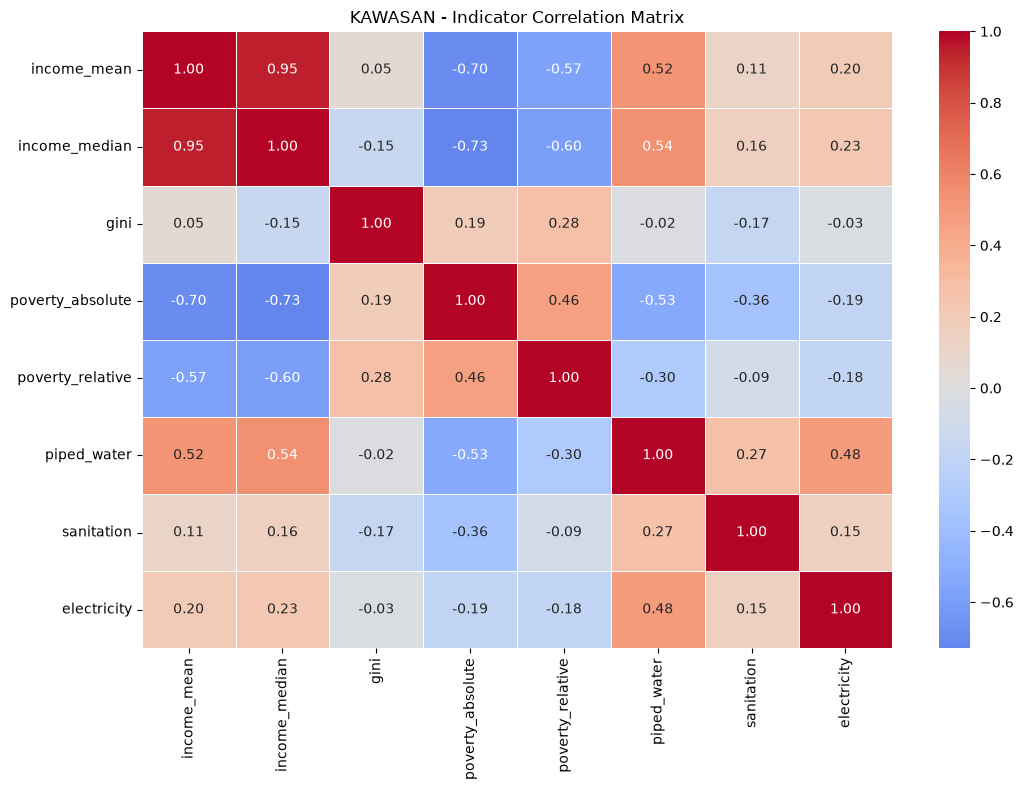

,income_mean,income_median,gini,poverty_absolute,poverty_relative,piped_water,sanitation,electricity
income_mean,1.000,0.950,0.052,-0.698,-0.574,0.523,0.113,0.196
income_median,0.950,1.000,-0.154,-0.729,-0.597,0.541,0.160,0.225
gini,0.052,-0.154,1.000,0.194,0.283,-0.016,-0.166,-0.028
poverty_absolute,-0.698,-0.729,0.194,1.000,0.462,-0.533,-0.360,-0.189
poverty_relative,-0.574,-0.597,0.283,0.462,1.000,-0.297,-0.094,-0.180
piped_water,0.523,0.541,-0.016,-0.533,-0.297,1.000,0.265,0.484
sanitation,0.113,0.160,-0.166,-0.360,-0.094,0.265,1.000,0.153
electricity,0.196,0.225,-0.028,-0.189,-0.180,0.484,0.153,1.000


In [17]:
# KAWASAN - Indicator Correlation Analysis

indicators = [
    "income_mean",
    "income_median",
    "gini",
    "poverty_absolute",
    "poverty_relative",
    "piped_water",
    "sanitation",
    "electricity"
]

correlation = master[indicators].corr(method="spearman")

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("KAWASAN - Indicator Correlation Matrix")
plt.tight_layout()
plt.show()

display(correlation.round(3))

In [18]:
# Check concentration of infrastructure values

infrastructure = [
    "piped_water",
    "sanitation",
    "electricity"
]

for column in infrastructure:
    print(f"\n{column}")
    print("Exactly 100%:", (master[column] == 100).sum())
    print("At least 99%:", (master[column] >= 99).sum())
    print("Below 90%:", (master[column] < 90).sum())


piped_water
Exactly 100%: 64
At least 99%: 77
Below 90%: 44

sanitation
Exactly 100%: 139
At least 99%: 147
Below 90%: 0

electricity
Exactly 100%: 133
At least 99%: 137
Below 90%: 6


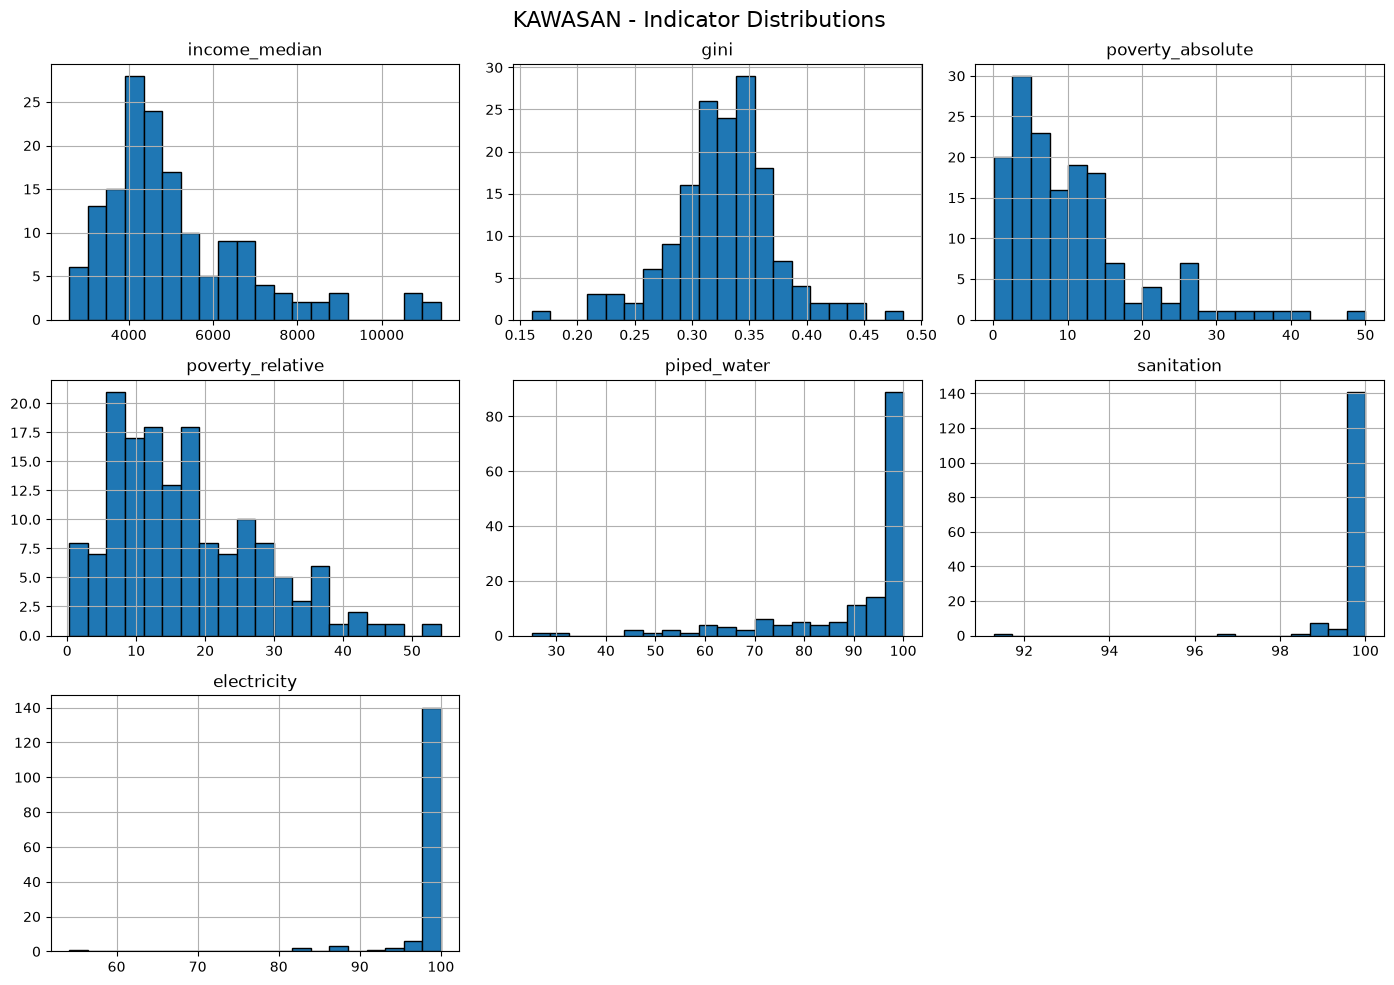


INCOME_MEDIAN

Lowest 5:


,state_clean,district_clean,income_median
105,sarawak,bukit mabong,2589
87,sabah,pitas,2785
79,sabah,kota marudu,2877
27,kelantan,kuala krai,2994
24,kelantan,jeli,3008



Highest 5:


,state_clean,district_clean,income_median
146,selangor,hulu langat,11404
145,selangor,sepang,11131
139,selangor,gombak,10777
143,selangor,petaling,10688
141,selangor,kuala langat,10583



GINI

Lowest 5:


,state_clean,district_clean,gini
141,selangor,kuala langat,0.160
154,terengganu,setiu,0.214
25,kelantan,kecil lojing,0.218
146,selangor,hulu langat,0.219
137,sarawak,telang usan,0.229


... (18 outputs left out)


ELECTRICITY

Lowest 5:


,state_clean,district_clean,electricity
105,sarawak,bukit mabong,54.17
131,sarawak,song,81.69
73,sabah,beluran,82.95
111,sarawak,kapit,86.64
87,sabah,pitas,86.96



Highest 5:


,state_clean,district_clean,electricity
0,johor,batu pahat,100.0
1,johor,johor bahru,100.0
2,johor,kluang,100.0
3,johor,kota tinggi,100.0
4,johor,kulai,100.0


In [19]:
# KAWASAN - Indicator distribution analysis

selected_indicators = [
    "income_median",
    "gini",
    "poverty_absolute",
    "poverty_relative",
    "piped_water",
    "sanitation",
    "electricity"
]

# Histograms
master[selected_indicators].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "KAWASAN - Indicator Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()


# Identify the 5 highest and lowest districts
for column in selected_indicators:

    print(f"\n{'=' * 50}")
    print(column.upper())

    print("\nLowest 5:")
    display(
        master.nsmallest(5, column)[
            ["state_clean", "district_clean", column]
        ]
    )

    print("\nHighest 5:")
    display(
        master.nlargest(5, column)[
            ["state_clean", "district_clean", column]
        ]
    )

In [20]:
# KAWASAN - IQR Outlier Detection

indicators = [
    "income_median",
    "gini",
    "poverty_absolute",
    "poverty_relative",
    "piped_water",
    "sanitation",
    "electricity"
]

outlier_results = []

for column in indicators:

    Q1 = master[column].quantile(0.25)
    Q3 = master[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = master[
        (master[column] < lower_bound) |
        (master[column] > upper_bound)
    ]

    outlier_results.append({
        "Indicator": column,
        "Lower Bound": round(lower_bound, 3),
        "Upper Bound": round(upper_bound, 3),
        "Outlier Count": len(outliers)
    })

    print(f"\n{column.upper()}")

    display(
        outliers[
            ["state_clean", "district_clean", column]
        ]
    )

display(pd.DataFrame(outlier_results))


INCOME_MEDIAN


,state_clean,district_clean,income_median
1,johor,johor bahru,8977
67,pulau pinang,barat daya,8919
139,selangor,gombak,10777
140,selangor,klang,8837
141,selangor,kuala langat,10583
143,selangor,petaling,10688
145,selangor,sepang,11131
146,selangor,hulu langat,11404



GINI


,state_clean,district_clean,gini
25,kelantan,kecil lojing,0.218
74,sabah,kalabakan,0.447
78,sabah,kota kinabalu,0.426
82,sabah,kunak,0.484
89,sabah,ranau,0.441
137,sarawak,telang usan,0.229
141,selangor,kuala langat,0.160
146,selangor,hulu langat,0.219
154,terengganu,setiu,0.214



POVERTY_ABSOLUTE


,state_clean,district_clean,poverty_absolute
73,sabah,beluran,33.0
79,sabah,kota marudu,40.0
81,sabah,kudat,35.3
82,sabah,kunak,29.2
87,sabah,pitas,50.0
91,sabah,semporna,30.4
97,sabah,tongod,41.5


... (5 outputs left out)

,state_clean,district_clean,sanitation
44,pahang,bera,99.40
48,pahang,lipis,98.90
75,sabah,keningau,99.66
77,sabah,kota belud,99.45
78,sabah,kota kinabalu,99.01
79,sabah,kota marudu,98.89
81,sabah,kudat,99.41
82,sabah,kunak,96.86
83,sabah,lahad datu,99.06
87,sabah,pitas,98.91



ELECTRICITY


,state_clean,district_clean,electricity
73,sabah,beluran,82.95
74,sabah,kalabakan,96.43
75,sabah,keningau,99.32
83,sabah,lahad datu,99.75
87,sabah,pitas,86.96
89,sabah,ranau,95.86
91,sabah,semporna,98.91
92,sabah,sipitang,95.63
101,sarawak,belaga,90.91
104,sarawak,bintulu,99.47


,Indicator,Lower Bound,Upper Bound,Outlier Count
0,income_median,1155.500,8679.500,8
1,gini,0.232,0.424,9
2,poverty_absolute,-10.150,27.850,7
3,poverty_relative,-13.250,46.350,1
4,piped_water,70.413,117.752,18
5,sanitation,100.000,100.000,16
6,electricity,100.000,100.000,22


In [21]:
# Cross-check against HIES district dataset

hies = pd.read_csv(CSV_DIR / "hies_district.csv")

hies["year"] = pd.to_datetime(hies["date"]).dt.year
hies = hies[hies["year"] == 2024].copy()

hies["state_clean"] = hies["state"].str.strip().str.casefold()
hies["district_clean"] = hies["district"].apply(clean_district_name)

hies_check = hies[
    [
        "state_clean",
        "district_clean",
        "income_median",
        "gini",
        "poverty"
    ]
]

comparison = master.merge(
    hies_check,
    on=["state_clean", "district_clean"],
    how="left",
    validate="one_to_one",
    suffixes=("_master", "_hies")
)

checks = {
    "Median Income": ("income_median_master", "income_median_hies"),
    "Gini": ("gini_master", "gini_hies"),
    "Absolute Poverty": ("poverty_absolute", "poverty")
}

for name, (col1, col2) in checks.items():

    matched = comparison[col1].notna() & comparison[col2].notna()

    equal = np.isclose(
        comparison.loc[matched, col1],
        comparison.loc[matched, col2],
        atol=0.001
    )

    print(f"\n{name}")
    print("Matched districts:", matched.sum())
    print("Matching values:", equal.sum())
    print("Different values:", (~equal).sum())


Median Income
Matched districts: 155
Matching values: 155
Different values: 0

Gini
Matched districts: 155
Matching values: 155
Different values: 0

Absolute Poverty
Matched districts: 155
Matching values: 155
Different values: 0


In [22]:
district_lookup = pd.read_csv(CSV_DIR / "state_district.csv")

print("Shape:", district_lookup.shape)
display(district_lookup.head(10))
print("\nColumns:")
print(district_lookup.columns.tolist())


FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\Muhd Haziq\\KAWASAN\\data\\raw\\csv\\state_district.csv'

In [23]:
# List all CSV files in the raw data folder

for file in RAW_DATA.rglob("*.csv"):
    print(file)

NameError: name 'RAW_DATA' is not defined

In [24]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_DATA = PROJECT_DIR / "data" / "raw"
CSV_DIR = RAW_DATA / "csv"

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DATA)

Project directory: c:\Users\Muhd Haziq\KAWASAN
Raw data directory: c:\Users\Muhd Haziq\KAWASAN\data\raw


In [25]:
for file in RAW_DATA.rglob("*.csv"):
    print(file)

c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\completion_school_district.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\cpi_2d_state.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\enrolment_school_district.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\formal_wages_state.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\gdp_district_real_supply.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\gdp_state_real_supply.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\hh_access_amenities.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\hh_access_internet.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\hh_income_district.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\hh_inequality_district.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\hh_poverty_district.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\hies_district.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\icths_internet_strata.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\lfs_district.csv
c:\Users\Muhd Haziq\KAWASAN\data\raw\csv\lfs_qtr_state.csv
c:\Users\Muhd Haziq\KAWASAN\d

In [26]:
district_lookup = pd.read_csv(CSV_DIR / "census_district.csv")

print("Shape:", district_lookup.shape)
print("\nColumns:")
print(district_lookup.columns.tolist())

display(district_lookup.head(10))

Shape: (960, 51)

Columns:
['state', 'code_state', 'district', 'code_district', 'code_state_district', 'year', 'population_total', 'area_km2', 'population_growth', 'housing_total', 'housing_occupied', 'housing_empty', 'household_total', 'household_size_avg', 'sex_male', 'sex_female', 'nationality_citizen', 'nationality_non_citizen', 'ethnicity_bumi', 'ethnicity_chinese', 'ethnicity_indian', 'ethnicity_other', 'age_0_14', 'age_15_64', 'age_65_above', 'marital_of_age', 'marital_never_married', 'marital_married', 'marital_widowed', 'marital_separated', 'marital_unknown', 'religion_muslim', 'religion_christian', 'religion_buddhist', 'religion_hindu', 'religion_other', 'religion_atheist', 'religion_unknown', 'density_urban', 'density_rural', 'Unnamed: 40', 'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43', 'Unnamed: 44', 'Unnamed: 45', 'Unnamed: 46', 'Unnamed: 47', 'Unnamed: 48', 'Unnamed: 49', 'Unnamed: 50']


,state,code_state,district,code_district,code_state_district,year,population_total,area_km2,population_growth,housing_total,housing_occupied,housing_empty,household_total,household_size_avg,sex_male,sex_female,nationality_citizen,nationality_non_citizen,ethnicity_bumi,ethnicity_chinese,ethnicity_indian,ethnicity_other,age_0_14,age_15_64,age_65_above,marital_of_age,marital_never_married,marital_married,marital_widowed,marital_separated,marital_unknown,religion_muslim,religion_christian,religion_buddhist,religion_hindu,religion_other,religion_atheist,religion_unknown,density_urban,density_rural,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48,Unnamed: 49,Unnamed: 50
0,Johor,1,Batu Pahat,1,1_1,1970,249596.0,1966,NaN,NaN,NaN,NaN,NaN,NaN,122454.0,127142.0,249596.0,NaN,162801.0,82116.0,4485.0,194.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Johor,1,Batu Pahat,1,1_1,1980,274625.0,1966,1.0,NaN,NaN,NaN,NaN,NaN,134233.0,140392.0,274625.0,NaN,171498.0,97637.0,5301.0,189.0,112280.0,151068.0,11277.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64727.0,209898.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Johor,1,Batu Pahat,1,1_1,1991,294056.0,1966,0.7,66791.0,58132.0,8659.0,59369.0,4.9,145922.0,148134.0,290877.0,3179.0,133958.0,103953.0,5536.0,47430.0,102996.0,176238.0,14822.0,224391.0,102010.0,108892.0,12265.0,1224.0,NaN,184458.0,3377.0,78549.0,4401.0,20562,1435.0,948.0,96335.0,197721.0,NaN,NaN,NaN,NaN,NaN,NaN,state,district,code_state,code_district,code_state_district
3,Johor,1,Batu Pahat,1,1_1,2000,336509.0,1966,1.3,87184.0,71634.0,15550.0,72434.0,4.6,170374.0,166135.0,328050.0,8459.0,216575.0,105480.0,5525.0,470.0,109112.0,207499.0,19898.0,227397.0,77343.0,135002.0,13904.0,1148.0,NaN,225280.0,3639.0,89968.0,4723.0,11748,770.0,381.0,161508.0,175001.0,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Batu Pahat,1,1,1_1
4,Johor,1,Batu Pahat,1,1_1,2010,401902.0,1966,1.8,107904.0,90396.0,17508.0,91198.0,4.3,206220.0,195682.0,383391.0,18511.0,256719.0,119361.0,6443.0,868.0,112129.0,261213.0,28560.0,289773.0,105366.0,162267.0,20416.0,1724.0,NaN,267911.0,5118.0,116380.0,6824.0,3173,663.0,1833.0,221888.0,180014.0,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Johor Bahru,1,2,1_2
5,Johor,1,Batu Pahat,1,1_1,2020,495338.0,1966,2.1,129486.0,105356.0,24130.0,116252.0,4.0,261609.0,233729.0,465143.0,30195.0,316367.0,140103.0,6910.0,1763.0,105923.0,356460.0,32955.0,389415.0,159048.0,211339.0,13635.0,5010.0,383.0,330803.0,14565.0,129831.0,13484.0,5570,1085.0,NaN,309750.0,185588.0,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Kluang,1,3,1_3
6,Johor,1,Johor Bahru,2,1_2,1970,267913.0,1066,NaN,NaN,NaN,NaN,NaN,NaN,136870.0,131043.0,267913.0,NaN,122373.0,112017.0,29212.0,4311.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Kota Tinggi,1,4,1_4
7,Johor,1,Johor Bahru,2,1_2,1980,406871.0,1066,4.2,NaN,NaN,NaN,NaN,NaN,208189.0,198682.0,406871.0,NaN,206085.0,161615.0,37956.0,1215.0,149163.0,244479.0,13229.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,270022.0,136849.0,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Mersing,1,5,1_5
8,Johor,1,Johor Bahru,2,1_2,1991,704471.0,1066,5.5,184488.0,141534.0,42954.0,150938.0,4.6,366337.0,338134.0,678287.0,26184.0,329359.0,260493.0,64923.0,23512.0,229812.0,456055.0,18604.0,536860.0,248101.0,269251.0,16602.0,2906.0,NaN,376354.0,19029.0,196853.0,55420.0,46926,5469.0,2632.0,560227.0,144244.0,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Muar,1,6,1_6
9,Johor,1,Johor Bahru,2,1_2,2000,1081978.0,1066,4.3,303419.0,238508.0,64911.0,246082.0,4.3,564466.0,517512.0,1017892.0,64086.0,521248.0,387522.0,101827.0,7295.0,327529.0,727994.0,26455.0,754449.0,289176.0,436574.0,23984.0,4715.0,NaN,577765.0,35139.0,336341.0,90901.0,28854,6565.0,6413.0,985407.0,96571.0,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Pontian,1,7,1_7


In [27]:
# Check how many non-empty values each column contains
print(district_lookup.count().to_string())

# Inspect rows containing data in the extra columns
extra_cols = [
    col for col in district_lookup.columns
    if col.startswith("Unnamed:")
]

display(
    district_lookup.loc[
        district_lookup[extra_cols].notna().any(axis=1),
        ["state", "district", "year"] + extra_cols
    ].head(15)
)

state                      960
code_state                 960
district                   960
code_district              960
code_state_district        960
year                       960
population_total           809
area_km2                   960
population_growth          648
housing_total              572
housing_occupied           572
housing_empty              571
household_total            572
household_size_avg         572
sex_male                   809
sex_female                 809
nationality_citizen        809
nationality_non_citizen    572
ethnicity_bumi             809
ethnicity_chinese          809
ethnicity_indian           760
ethnicity_other            806
age_0_14                   698
age_15_64                  698
age_65_above               698
marital_of_age             572
marital_never_married      572
marital_married            572
marital_widowed            572
marital_separated          572
marital_unknown            127
religion_muslim            572
religion

,state,district,year,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48,Unnamed: 49,Unnamed: 50
2,Johor,Batu Pahat,1991,NaN,NaN,NaN,NaN,NaN,NaN,state,district,code_state,code_district,code_state_district
3,Johor,Batu Pahat,2000,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Batu Pahat,1,1,1_1
4,Johor,Batu Pahat,2010,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Johor Bahru,1,2,1_2
5,Johor,Batu Pahat,2020,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Kluang,1,3,1_3
6,Johor,Johor Bahru,1970,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Kota Tinggi,1,4,1_4
7,Johor,Johor Bahru,1980,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Mersing,1,5,1_5
8,Johor,Johor Bahru,1991,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Muar,1,6,1_6
9,Johor,Johor Bahru,2000,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Pontian,1,7,1_7
10,Johor,Johor Bahru,2010,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Segamat,1,8,1_8
11,Johor,Johor Bahru,2020,NaN,NaN,NaN,NaN,NaN,NaN,Johor,Kulai,1,9,1_9


In [28]:
print("Years available:")
print(sorted(district_lookup["year"].dropna().unique()))

print("\nUnique state-district pairs:")
print(
    district_lookup[["state", "district"]]
    .drop_duplicates()
    .shape[0]
)

print("\nUnique district codes:")
print(district_lookup["code_state_district"].nunique())

Years available:
[np.int64(1970), np.int64(1980), np.int64(1991), np.int64(2000), np.int64(2010), np.int64(2020)]

Unique state-district pairs:
160

Unique district codes:
160


In [29]:
# Keep only the five geographical reference columns
district_lookup_clean = (
    district_lookup[
        [
            "state",
            "code_state",
            "district",
            "code_district",
            "code_state_district"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Lookup shape:", district_lookup_clean.shape)
print("Duplicate district codes:",
      district_lookup_clean["code_state_district"].duplicated().sum())

display(district_lookup_clean.head(10))

Lookup shape: (160, 5)
Duplicate district codes: 0


,state,code_state,district,code_district,code_state_district
0,Johor,1,Batu Pahat,1,1_1
1,Johor,1,Johor Bahru,2,1_2
2,Johor,1,Kluang,3,1_3
3,Johor,1,Kota Tinggi,4,1_4
4,Johor,1,Mersing,5,1_5
5,Johor,1,Muar,6,1_6
6,Johor,1,Pontian,7,1_7
7,Johor,1,Segamat,8,1_8
8,Johor,1,Kulai,9,1_9
9,Johor,1,Tangkak,10,1_10


In [30]:
# Standardise names for comparison
district_lookup_clean["state_clean"] = (
    district_lookup_clean["state"].str.strip().str.casefold()
)

district_lookup_clean["district_clean"] = (
    district_lookup_clean["district"].apply(clean_district_name)
)

# Compare against our existing master dataset
geo_check = master.merge(
    district_lookup_clean[
        ["state_clean", "district_clean", "code_state_district"]
    ],
    on=["state_clean", "district_clean"],
    how="left",
    validate="one_to_one"
)

print("Total master districts:", len(geo_check))
print("Matched districts:", geo_check["code_state_district"].notna().sum())
print("Unmatched districts:", geo_check["code_state_district"].isna().sum())

display(
    geo_check.loc[
        geo_check["code_state_district"].isna(),
        ["state_clean", "district_clean"]
    ]
)

Total master districts: 155
Matched districts: 155
Unmatched districts: 0


,state_clean,district_clean


In [31]:
# Merge all geographic codes into the master dataset
master_geo = master.merge(
    district_lookup_clean[
        [
            "state_clean",
            "district_clean",
            "code_state",
            "code_district",
            "code_state_district"
        ]
    ],
    on=["state_clean", "district_clean"],
    how="left",
    validate="one_to_one"
)

print("Master dataset with geographic codes:", master_geo.shape)
display(master_geo.head())

Master dataset with geographic codes: (155, 14)


,state_clean,district_clean,income_mean,income_median,gini,poverty_absolute,poverty_relative,piped_water,sanitation,electricity,population,code_state,code_district,code_state_district
0,johor,batu pahat,9006,7555,0.316,2.4,11.6,100.00,100.0,100.0,510.1,1,1,1_1
1,johor,johor bahru,10975,8977,0.350,1.9,9.9,99.99,100.0,100.0,1799.1,1,2,1_2
2,johor,kluang,6616,6158,0.292,5.7,24.8,98.73,100.0,100.0,333.7,1,3,1_3
3,johor,kota tinggi,8106,6284,0.379,4.2,22.7,99.83,100.0,100.0,233.5,1,4,1_4
4,johor,kulai,10296,8406,0.319,0.1,6.3,100.00,100.0,100.0,351.3,1,9,1_9


In [32]:
# Create processed folder if it doesn't exist
(PROJECT_DIR / "data" / "processed").mkdir(
    parents=True, exist_ok=True
)

master_geo.to_csv(
    PROJECT_DIR / "data" / "processed" / "master_2024_with_geo_codes.csv",
    index=False
)

print("Master dataset saved successfully!")

Master dataset saved successfully!


In [33]:
import json

geojson_path = GEOJSON_DIR / "administrative_2_district.geojson"

with open(geojson_path, "r", encoding="utf-8") as f:
    geojson_data = json.load(f)

print("File loaded successfully!")
print("Number of features:", len(geojson_data["features"]))
print("\nFirst feature properties:")
print(geojson_data["features"][0]["properties"])

NameError: name 'GEOJSON_DIR' is not defined

In [34]:
GEOJSON_DIR = RAW_DATA / "geojson"

print("GeoJSON folder:", GEOJSON_DIR)
print("Folder exists:", GEOJSON_DIR.exists())

GeoJSON folder: c:\Users\Muhd Haziq\KAWASAN\data\raw\geojson
Folder exists: False


In [35]:
GEOJSON_DIR = RAW_DATA / "geojson"
GEOJSON_DIR.mkdir(parents=True, exist_ok=True)

print("GeoJSON folder created:", GEOJSON_DIR.exists())

GeoJSON folder created: True


In [36]:
print([file.name for file in GEOJSON_DIR.iterdir()])

['administrative_2_district.geojson']


In [37]:
import json

geojson_path = GEOJSON_DIR / "administrative_2_district.geojson"

with open(geojson_path, "r", encoding="utf-8") as f:
    geojson_data = json.load(f)

print("File loaded successfully!")
print("Number of features:", len(geojson_data["features"]))
print("\nFirst feature properties:")
print(geojson_data["features"][0]["properties"])

File loaded successfully!
Number of features: 160

First feature properties:
{'state': 'Johor', 'district': 'Batu Pahat', 'code_state': 1, 'code_district': 1, 'code_state_district': '1_1'}


In [38]:
geojson_districts = pd.DataFrame([
    feature["properties"]
    for feature in geojson_data["features"]
])

print("GeoJSON district records:", len(geojson_districts))
print("Unique district codes:", geojson_districts["code_state_district"].nunique())
print("Duplicate district codes:", geojson_districts["code_state_district"].duplicated().sum())

GeoJSON district records: 160
Unique district codes: 160
Duplicate district codes: 0


In [39]:
geojson_codes = set(geojson_districts["code_state_district"])
master_codes = set(master_geo["code_state_district"])

matched = master_codes & geojson_codes
unmatched = master_codes - geojson_codes

print("Master dataset districts:", len(master_codes))
print("Matched with GeoJSON:", len(matched))
print("Unmatched:", len(unmatched))
print("Match rate:", round(len(matched) / len(master_codes) * 100, 2), "%")

if unmatched:
    print("\nUnmatched district codes:")
    print(unmatched)

Master dataset districts: 155
Matched with GeoJSON: 155
Unmatched: 0
Match rate: 100.0 %


In [40]:
master_codes = set(master_geo["code_state_district"])

geojson_155 = {
    "type": "FeatureCollection",
    "features": [
        feature
        for feature in geojson_data["features"]
        if feature["properties"]["code_state_district"] in master_codes
    ]
}

print("Filtered boundaries:", len(geojson_155["features"]))

Filtered boundaries: 155


In [41]:
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

output_path = PROCESSED_DIR / "kawasan_district_boundaries.geojson"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(geojson_155, f)

print("Saved successfully:", output_path)

Saved successfully: c:\Users\Muhd Haziq\KAWASAN\data\processed\kawasan_district_boundaries.geojson


In [42]:
# Convert master dataset into JSON-compatible records
records = json.loads(master_geo.to_json(orient="records"))

# Create a lookup using official district codes
indicator_lookup = {
    str(row["code_state_district"]): row
    for row in records
}

# Add indicators to each district boundary
for feature in geojson_155["features"]:
    code = str(feature["properties"]["code_state_district"])
    indicators = indicator_lookup[code]

    for column, value in indicators.items():
        if column not in [
            "state_clean",
            "district_clean",
            "code_state",
            "code_district",
            "code_state_district"
        ]:
            feature["properties"][column] = value

print("Enrichment completed!")
print("Districts enriched:", len(geojson_155["features"]))
print("\nSample enriched properties:")
print(geojson_155["features"][0]["properties"])

Enrichment completed!
Districts enriched: 155

Sample enriched properties:
{'state': 'Johor', 'district': 'Batu Pahat', 'code_state': 1, 'code_district': 1, 'code_state_district': '1_1', 'income_mean': 9006, 'income_median': 7555, 'gini': 0.316, 'poverty_absolute': 2.4, 'poverty_relative': 11.6, 'piped_water': 100.0, 'sanitation': 100.0, 'electricity': 100.0, 'population': 510.1}


In [43]:
output_path = PROCESSED_DIR / "kawasan_2024_indicators.geojson"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(geojson_155, f)

print("Saved:", output_path)

Saved: c:\Users\Muhd Haziq\KAWASAN\data\processed\kawasan_2024_indicators.geojson


In [44]:
indicator_columns = [
    "income_mean",
    "income_median",
    "gini",
    "poverty_absolute",
    "poverty_relative",
    "piped_water",
    "sanitation",
    "electricity",
    "population"
]

validation_results = []

for feature in geojson_155["features"]:
    properties = feature["properties"]

    missing = [
        column for column in indicator_columns
        if column not in properties or properties[column] is None
    ]

    validation_results.append({
        "district": properties["district"],
        "missing_indicators": len(missing)
    })

validation_df = pd.DataFrame(validation_results)

print("Total districts:", len(validation_df))
print("Districts with complete indicators:",
      (validation_df["missing_indicators"] == 0).sum())
print("Districts with missing indicators:",
      (validation_df["missing_indicators"] > 0).sum())

Total districts: 155
Districts with complete indicators: 155
Districts with missing indicators: 0


In [45]:
krdi_data = master_geo.copy()

positive_indicators = [
    "income_median",
    "piped_water",
    "sanitation",
    "electricity"
]

negative_indicators = [
    "poverty_absolute",
    "poverty_relative",
    "gini"
]

# Normalise positive indicators
for col in positive_indicators:
    krdi_data[col + "_score"] = (
        (krdi_data[col] - krdi_data[col].min()) /
        (krdi_data[col].max() - krdi_data[col].min())
    ) * 100

# Normalise negative indicators
for col in negative_indicators:
    krdi_data[col + "_score"] = (
        (krdi_data[col].max() - krdi_data[col]) /
        (krdi_data[col].max() - krdi_data[col].min())
    ) * 100

print("Normalisation completed!")

Normalisation completed!


In [46]:
score_columns = [
    "income_median_score",
    "poverty_absolute_score",
    "poverty_relative_score",
    "gini_score",
    "piped_water_score",
    "sanitation_score",
    "electricity_score"
]

print("Normalised score summary:")
display(krdi_data[score_columns].describe().round(2))

Normalised score summary:


,income_median_score,poverty_absolute_score,poverty_relative_score,gini_score,piped_water_score,sanitation_score,electricity_score
count,155.00,155.00,155.00,155.00,155.00,155.00,155.00
mean,28.74,79.37,69.06,48.29,87.26,98.24,97.61
std,19.81,17.65,19.75,13.98,20.42,8.96,10.10
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,15.75,72.95,56.03,40.74,84.22,100.00,100.00
50%,22.88,84.17,74.03,48.15,98.65,100.00,100.00
75%,37.08,91.98,83.67,55.56,100.00,100.00,100.00
max,100.00,100.00,100.00,100.00,100.00,100.00,100.00


In [47]:
print("Minimum score:", krdi_data[score_columns].min().min())
print("Maximum score:", krdi_data[score_columns].max().max())

display(
    krdi_data[
        ["state_clean", "district_clean"] + score_columns
    ].head(10).round(2)
)

Minimum score: 0.0
Maximum score: 100.0


,state_clean,district_clean,income_median_score,poverty_absolute_score,poverty_relative_score,gini_score,piped_water_score,sanitation_score,electricity_score
0,johor,batu pahat,56.34,95.39,79.04,51.85,100.00,100.0,100.0
1,johor,johor bahru,72.47,96.39,82.19,41.36,99.99,100.0,100.0
2,johor,kluang,40.49,88.78,54.55,59.26,98.31,100.0,100.0
3,johor,kota tinggi,41.92,91.78,58.44,32.41,99.77,100.0,100.0
4,johor,kulai,65.99,100.00,88.87,50.93,100.00,100.0,100.0
5,johor,mersing,31.15,86.77,54.17,68.21,93.85,100.0,100.0
6,johor,muar,53.83,95.99,70.69,54.94,100.00,100.0,100.0
7,johor,pontian,35.12,96.19,52.88,44.14,100.00,100.0,100.0
8,johor,segamat,43.81,93.99,69.39,59.26,99.39,100.0,100.0
9,johor,tangkak,42.94,92.18,64.94,54.94,100.00,100.0,100.0


In [48]:
variation_check = pd.DataFrame({
    "Unique Values": krdi_data[score_columns].nunique(),
    "Standard Deviation": krdi_data[score_columns].std(),
    "Districts at 100 (%)": (
        krdi_data[score_columns].eq(100).mean() * 100
    )
})

display(variation_check.round(2))

,Unique Values,Standard Deviation,Districts at 100 (%)
income_median_score,153,19.81,0.65
poverty_absolute_score,112,17.65,1.94
poverty_relative_score,117,19.75,1.29
gini_score,97,13.98,0.65
piped_water_score,91,20.42,41.29
sanitation_score,17,8.96,89.68
electricity_score,21,10.10,85.81


In [49]:
dimension_weights = {
    "economic_wellbeing": 0.50,
    "economic_equality": 0.20,
    "infrastructure": 0.30
}

indicator_weights = {
    "income_median_score": 0.20,
    "poverty_absolute_score": 0.15,
    "poverty_relative_score": 0.15,
    "gini_score": 0.20,
    "piped_water_score": 0.21,
    "sanitation_score": 0.045,
    "electricity_score": 0.045
}

print("Total indicator weight:",
      sum(indicator_weights.values()))

print("Total dimension weight:",
      sum(dimension_weights.values()))

display(pd.DataFrame({
    "Indicator": indicator_weights.keys(),
    "Weight (%)": [
        weight * 100
        for weight in indicator_weights.values()
    ]
}))

Total indicator weight: 1.0
Total dimension weight: 1.0


,Indicator,Weight (%)
0,income_median_score,20.0
1,poverty_absolute_score,15.0
2,poverty_relative_score,15.0
3,gini_score,20.0
4,piped_water_score,21.0
5,sanitation_score,4.5
6,electricity_score,4.5


In [50]:
# 1. Economic Well-being (50%)
krdi_data["economic_wellbeing_score"] = (
    krdi_data["income_median_score"] * 0.40 +
    krdi_data["poverty_absolute_score"] * 0.30 +
    krdi_data["poverty_relative_score"] * 0.30
)

# 2. Economic Equality (20%)
krdi_data["economic_equality_score"] = (
    krdi_data["gini_score"]
)

# 3. Infrastructure (30%)
krdi_data["infrastructure_score"] = (
    krdi_data["piped_water_score"] * 0.70 +
    krdi_data["sanitation_score"] * 0.15 +
    krdi_data["electricity_score"] * 0.15
)

print("Dimension scores calculated!")

display(
    krdi_data[
        [
            "state_clean",
            "district_clean",
            "economic_wellbeing_score",
            "economic_equality_score",
            "infrastructure_score"
        ]
    ].head(10).round(2)
)

Dimension scores calculated!


,state_clean,district_clean,economic_wellbeing_score,economic_equality_score,infrastructure_score
0,johor,batu pahat,74.86,51.85,100.00
1,johor,johor bahru,82.56,41.36,99.99
2,johor,kluang,59.19,59.26,98.81
3,johor,kota tinggi,61.83,32.41,99.84
4,johor,kulai,83.06,50.93,100.00
5,johor,mersing,54.74,68.21,95.70
6,johor,muar,71.54,54.94,100.00
7,johor,pontian,58.77,44.14,100.00
8,johor,segamat,66.54,59.26,99.57
9,johor,tangkak,64.31,54.94,100.00


In [51]:
krdi_data["KRDI"] = (
    krdi_data["economic_wellbeing_score"] * 0.50 +
    krdi_data["economic_equality_score"] * 0.20 +
    krdi_data["infrastructure_score"] * 0.30
)

print("Preliminary KRDI calculated!")
print("\nKRDI Summary:")

display(krdi_data["KRDI"].describe().round(2))

Preliminary KRDI calculated!

KRDI Summary:


count    155.00
mean      64.81
std       12.10
min       24.82
25%       58.34
50%       66.17
75%       73.16
max       97.55
Name: KRDI, dtype: float64

In [52]:
district_rankings = krdi_data[
    ["state_clean", "district_clean", "KRDI"]
].sort_values("KRDI", ascending=False)

print("TOP 10 DISTRICTS")
display(district_rankings.head(10).round(2))

print("BOTTOM 10 DISTRICTS")
display(district_rankings.tail(10).sort_values("KRDI").round(2))

TOP 10 DISTRICTS


,state_clean,district_clean,KRDI
141,selangor,kuala langat,97.55
146,selangor,hulu langat,96.36
145,selangor,sepang,88.54
139,selangor,gombak,82.61
151,terengganu,kuala nerus,82.13
140,selangor,klang,82.07
4,johor,kulai,81.71
154,terengganu,setiu,81.25
143,selangor,petaling,81.17
147,selangor,hulu selangor,80.14


BOTTOM 10 DISTRICTS


,state_clean,district_clean,KRDI
87,sabah,pitas,24.82
105,sarawak,bukit mabong,26.96
79,sabah,kota marudu,34.19
89,sabah,ranau,34.55
108,sarawak,julau,37.26
97,sabah,tongod,37.44
131,sarawak,song,38.67
91,sabah,semporna,39.18
74,sabah,kalabakan,41.40
111,sarawak,kapit,43.42


In [53]:
# Select top 5 and bottom 5 districts
top_5 = krdi_data.nlargest(5, "KRDI")
bottom_5 = krdi_data.nsmallest(5, "KRDI")

# Columns to inspect
analysis_columns = [
    "state_clean",
    "district_clean",
    "KRDI",
    "economic_wellbeing_score",
    "economic_equality_score",
    "infrastructure_score",
    "income_median_score",
    "poverty_absolute_score",
    "poverty_relative_score",
    "gini_score",
    "piped_water_score",
    "sanitation_score",
    "electricity_score"
]

print("TOP 5 DISTRICTS")
display(top_5[analysis_columns].round(2))

print("BOTTOM 5 DISTRICTS")
display(bottom_5[analysis_columns].round(2))

TOP 5 DISTRICTS


,state_clean,district_clean,KRDI,economic_wellbeing_score,economic_equality_score,infrastructure_score,income_median_score,poverty_absolute_score,poverty_relative_score,gini_score,piped_water_score,sanitation_score,electricity_score
141,selangor,kuala langat,97.55,95.10,100.00,100.00,90.69,99.60,96.47,100.00,100.00,100.0,100.0
146,selangor,hulu langat,96.36,100.00,81.79,100.00,100.00,100.00,100.00,81.79,100.00,100.0,100.0
145,selangor,sepang,88.54,98.32,46.91,100.00,96.90,100.00,98.52,46.91,100.00,100.0,100.0
139,selangor,gombak,82.61,90.66,36.42,99.97,92.89,95.99,82.37,36.42,99.96,100.0,100.0
151,terengganu,kuala nerus,82.13,79.32,62.35,100.00,53.49,96.99,96.10,62.35,100.00,100.0,100.0


BOTTOM 5 DISTRICTS


,state_clean,district_clean,KRDI,economic_wellbeing_score,economic_equality_score,infrastructure_score,income_median_score,poverty_absolute_score,poverty_relative_score,gini_score,piped_water_score,sanitation_score,electricity_score
87,sabah,pitas,24.82,6.23,22.53,57.33,2.22,0.00,17.81,22.53,47.83,87.49,71.55
105,sarawak,bukit mabong,26.96,26.27,46.60,15.00,0.00,87.58,0.00,46.60,0.00,100.00,0.00
79,sabah,kota marudu,34.19,15.89,19.44,74.51,3.27,20.04,28.57,19.44,66.32,87.26,100.00
89,sabah,ranau,34.55,34.57,13.27,48.69,9.99,53.11,48.79,13.27,28.64,100.00,90.97
108,sarawak,julau,37.26,26.15,38.27,55.11,7.66,46.89,30.06,38.27,35.87,100.00,100.00


In [54]:
# Create output directory
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export integrated dataset
master_geo.to_csv(
    OUTPUT_DIR / "KAWASAN_Integrated_Dataset_2024.csv",
    index=False
)

# Export Excel version
master_geo.to_excel(
    OUTPUT_DIR / "KAWASAN_Integrated_Dataset_2024.xlsx",
    index=False
)

print("Dataset exported successfully!")

Dataset exported successfully!


In [55]:
candidate_datasets = [
    "enrolment_school_district.csv",
    "completion_school_district.csv",
    "schools_district.csv",
    "teachers_district.csv",
    "lfs_district.csv",
    "hh_access_internet.csv",
    "icths_internet_strata.csv"
]

for filename in candidate_datasets:
    file_path = CSV_DIR / filename

    df = pd.read_csv(file_path)

    print("\n" + "=" * 70)
    print("DATASET:", filename)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Sample:")
    display(df.head(3))


DATASET: enrolment_school_district.csv
Shape: (12756, 6)
Columns: ['state', 'district', 'stage', 'sex', 'date', 'students']
Sample:


,state,district,stage,sex,date,students
0,Malaysia,All Districts,primary,both,2017-01-01,2689810
1,Malaysia,All Districts,primary,both,2018-01-01,2694779
2,Malaysia,All Districts,primary,both,2019-01-01,2729704



DATASET: completion_school_district.csv
Shape: (2355, 5)
Columns: ['state', 'district', 'stage', 'date', 'completion']
Sample:


,state,district,stage,date,completion
0,Johor,All Districts,primary,2021-01-01,98.0
1,Johor,All Districts,primary,2022-01-01,96.9
2,Johor,All Districts,primary,2023-01-01,97.5



DATASET: schools_district.csv
Shape: (4514, 6)
Columns: ['state', 'district', 'stage', 'type', 'date', 'schools']
Sample:


,state,district,stage,type,date,schools
0,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2017-01-01,7776
1,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2018-01-01,7774
2,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2019-01-01,7773


... (4 outputs left out)


DATASET: hh_access_internet.csv
Shape: (343, 4)
Columns: ['date', 'state', 'strata', 'proportion']
Sample:


,date,state,strata,proportion
0,2019-01-01,Malaysia,overall,89.6
1,2020-01-01,Malaysia,overall,91.0
2,2021-01-01,Malaysia,overall,94.9



DATASET: icths_internet_strata.csv
Shape: (392, 4)
Columns: ['date', 'state', 'strata', 'proportion']
Sample:


,date,state,strata,proportion
0,2018-01-01,Malaysia,overall,81.2
1,2019-01-01,Malaysia,overall,84.2
2,2020-01-01,Malaysia,overall,89.6


In [56]:
education_files = [
    "enrolment_school_district.csv",
    "completion_school_district.csv",
    "schools_district.csv",
    "teachers_district.csv"
]

for filename in education_files:
    df = pd.read_csv(CSV_DIR / filename)

    print(f"\n{'='*60}")
    print(filename)

    print("Years:")
    print(sorted(df["date"].str[:4].unique()))

    print("\nDistrict coverage:")
    print("Unique districts:", df["district"].nunique())
    print(df["district"].unique()[:15])

    if "stage" in df.columns:
        print("\nStages:")
        print(df["stage"].unique())

    if "sex" in df.columns:
        print("\nSex:")
        print(df["sex"].unique())

    if "type" in df.columns:
        print("\nTypes:")
        print(df["type"].unique())

    print("\nMissing values:")
    print(df.isnull().sum())


enrolment_school_district.csv
Years:
['2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']

District coverage:
Unique districts: 172
<StringArray>
['All Districts',    'Batu Pahat',   'Johor Bahru',        'Kluang',
   'Kota Tinggi',         'Kulai',       'Mersing',          'Muar',
       'Pontian',       'Segamat',       'Tangkak',  'Pasir Gudang',
        'Baling', 'Bandar Baharu',    'Kota Setar']
Length: 15, dtype: str

Stages:
<StringArray>
['primary', 'secondary', 'post_secondary']
Length: 3, dtype: str

Sex:
<StringArray>
['both', 'female', 'male']
Length: 3, dtype: str

Missing values:
state       0
district    0
stage       0
sex         0
date        0
students    0
dtype: int64

completion_school_district.csv
Years:
['2021', '2022', '2023', '2024', '2025']

District coverage:
Unique districts: 142
<StringArray>
[ 'All Districts',     'Batu Pahat',    'Johor Bahru',         'Kluang',
    'Kota Tinggi',          'Kulai',        'Mersing',           'Muar'

In [57]:
education_files = {
    "enrolment": "enrolment_school_district.csv",
    "completion": "completion_school_district.csv",
    "schools": "schools_district.csv",
    "teachers": "teachers_district.csv"
}

for name, filename in education_files.items():

    df = pd.read_csv(CSV_DIR / filename)
    df["year"] = pd.to_datetime(df["date"]).dt.year

    data_2024 = df[df["year"] == 2024].copy()

    # Remove national aggregate
    data_2024 = data_2024[
        data_2024["district"] != "All Districts"
    ]

    # Use overall sex category where available
    if "sex" in data_2024.columns:
        data_2024 = data_2024[
            data_2024["sex"] == "both"
        ]

    print("\n" + "=" * 60)
    print(name.upper())

    print("2024 records:", len(data_2024))
    print("Unique districts:", data_2024["district"].nunique())

    print("States:", data_2024["state"].nunique())

    print("\nDuplicate records:")
    print(data_2024.duplicated().sum())

    print("\nSample:")
    display(data_2024.head(5))


ENROLMENT
2024 records: 429
Unique districts: 143
States: 16

Duplicate records:
0

Sample:


,state,district,stage,sex,date,students,year
163,Johor,Batu Pahat,primary,both,2024-06-30,34851,2024
190,Johor,Batu Pahat,secondary,both,2024-06-30,27209,2024
216,Johor,Batu Pahat,post_secondary,both,2024-06-30,1029,2024
241,Johor,Johor Bahru,primary,both,2024-06-30,76956,2024
268,Johor,Johor Bahru,secondary,both,2024-06-30,49824,2024



COMPLETION
2024 records: 423
Unique districts: 141
States: 13

Duplicate records:
0

Sample:


,state,district,stage,date,completion,year
18,Johor,Batu Pahat,primary,2024-01-01,99.4,2024
23,Johor,Batu Pahat,secondary_lower,2024-01-01,97.7,2024
28,Johor,Batu Pahat,secondary_upper,2024-01-01,98.1,2024
33,Johor,Johor Bahru,primary,2024-01-01,95.9,2024
38,Johor,Johor Bahru,secondary_lower,2024-01-01,99.7,2024



SCHOOLS
2024 records: 451
Unique districts: 153
States: 16

Duplicate records:
0

Sample:


,state,district,stage,type,date,schools,year
88,Johor,Batu Pahat,primary,Sekolah Rendah Kerajaan,2024-06-30,144,2024
97,Johor,Batu Pahat,secondary,Sekolah Menengah Kerajaan,2024-06-30,31,2024
106,Johor,Batu Pahat,tertiary,IPTA,2024-01-01,1,2024
115,Johor,Johor Bahru,primary,Sekolah Rendah Kerajaan,2024-06-30,184,2024
124,Johor,Johor Bahru,secondary,Sekolah Menengah Kerajaan,2024-06-30,87,2024



TEACHERS
2024 records: 290
Unique districts: 145
States: 16

Duplicate records:
0

Sample:


,state,district,stage,sex,date,teachers,year
115,Johor,Batu Pahat,primary,both,2024-06-30,3428,2024
142,Johor,Batu Pahat,secondary,both,2024-06-30,2539,2024
169,Johor,Johor Bahru,primary,both,2024-06-30,5042,2024
196,Johor,Johor Bahru,secondary,both,2024-06-30,3899,2024
223,Johor,Kluang,primary,both,2024-06-30,2305,2024


In [58]:
lfs = pd.read_csv(CSV_DIR / "lfs_district.csv")

lfs["year"] = pd.to_datetime(lfs["date"]).dt.year

lfs_2024 = lfs[lfs["year"] == 2024].copy()

print("2024 employment records:", len(lfs_2024))
print("Unique districts:", lfs_2024["district"].nunique())

print("\nAvailable indicators:")
print(lfs.columns.tolist())

print("\nMissing values:")
print(lfs_2024.isnull().sum())

display(lfs_2024.head(10))

2024 employment records: 162
Unique districts: 162

Available indicators:
['state', 'district', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio', 'year']

Missing values:
state            0
district         0
date             0
lf               6
lf_employed      6
lf_unemployed    6
lf_outside       6
p_rate           6
u_rate           6
ep_ratio         6
year             0
dtype: int64


,state,district,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio,year
6,Johor,Batu Pahat,2024-01-01,263.6,260.2,3.4,108.2,70.9,1.3,70.0,2024
13,Johor,Johor Bahru,2024-01-01,921.3,896.3,25.0,314.1,74.6,2.7,72.6,2024
20,Johor,Kluang,2024-01-01,176.6,171.6,5.0,66.6,72.6,2.8,70.6,2024
27,Johor,Kota Tinggi,2024-01-01,119.6,116.7,2.9,46.3,72.1,2.4,70.3,2024
34,Johor,Kulai,2024-01-01,173.3,169.4,3.9,86.2,66.8,2.3,65.3,2024
41,Johor,Mersing,2024-01-01,35.4,34.7,0.7,22.3,61.3,2.0,60.1,2024
48,Johor,Muar,2024-01-01,161.4,158.7,2.6,71.2,69.4,1.6,68.2,2024
55,Johor,Pontian,2024-01-01,84.4,82.2,2.1,42.4,66.6,2.5,64.8,2024
62,Johor,Segamat,2024-01-01,108.9,106.2,2.8,43.9,71.3,2.5,69.5,2024
69,Johor,Tangkak,2024-01-01,82.0,80.6,1.4,42.3,65.9,1.7,64.8,2024


In [59]:
# Check existing masterlist columns
print("MASTER GEO COLUMNS:")
print(master_geo.columns.tolist())

print("\nMasterlist records:", len(master_geo))

MASTER GEO COLUMNS:
['state_clean', 'district_clean', 'income_mean', 'income_median', 'gini', 'poverty_absolute', 'poverty_relative', 'piped_water', 'sanitation', 'electricity', 'population', 'code_state', 'code_district', 'code_state_district']

Masterlist records: 155


In [60]:
def clean_geo_key(df):
    df = df.copy()

    df["state"] = (
        df["state"].astype(str).str.strip().str.lower()
    )

    df["district"] = (
        df["district"].astype(str).str.strip().str.lower()
    )

    return df


# Existing masterlist
master_keys = clean_geo_key(master_geo)

master_pairs = set(
    zip(master_keys["state"], master_keys["district"])
)

# Education and employment datasets
files = {
    "Enrolment": "enrolment_school_district.csv",
    "Completion": "completion_school_district.csv",
    "Schools": "schools_district.csv",
    "Teachers": "teachers_district.csv",
    "Employment": "lfs_district.csv"
}

for name, filename in files.items():

    df = pd.read_csv(CSV_DIR / filename)

    df["year"] = pd.to_datetime(df["date"]).dt.year
    df = df[df["year"] == 2024].copy()

    df = df[df["district"] != "All Districts"]

    if "sex" in df.columns:
        df = df[df["sex"] == "both"]

    df = clean_geo_key(df)

    dataset_pairs = set(
        zip(df["state"], df["district"])
    )

    matched = dataset_pairs & master_pairs
    unmatched = dataset_pairs - master_pairs

    print("\n" + "=" * 55)
    print(name.upper())

    print("Dataset districts:", len(dataset_pairs))
    print("Matched masterlist:", len(matched))
    print("Unmatched districts:", len(unmatched))

    if unmatched:
        print("\nUnmatched examples:")
        print(sorted(unmatched)[:15])

KeyError: 'state'

In [61]:
def clean_geo_key(df, state_col, district_col):
    df = df.copy()

    df["state_key"] = (
        df[state_col].astype(str).str.strip().str.lower()
    )

    df["district_key"] = (
        df[district_col].astype(str).str.strip().str.lower()
    )

    return df


# Existing masterlist
master_keys = clean_geo_key(
    master_geo,
    "state_clean",
    "district_clean"
)

master_pairs = set(
    zip(master_keys["state_key"], master_keys["district_key"])
)


# New datasets
files = {
    "Enrolment": "enrolment_school_district.csv",
    "Completion": "completion_school_district.csv",
    "Schools": "schools_district.csv",
    "Teachers": "teachers_district.csv",
    "Employment": "lfs_district.csv"
}

for name, filename in files.items():

    df = pd.read_csv(CSV_DIR / filename)

    df["year"] = pd.to_datetime(df["date"]).dt.year
    df = df[df["year"] == 2024].copy()

    df = df[df["district"] != "All Districts"]

    if "sex" in df.columns:
        df = df[df["sex"] == "both"]

    df = clean_geo_key(df, "state", "district")

    dataset_pairs = set(
        zip(df["state_key"], df["district_key"])
    )

    matched = dataset_pairs & master_pairs
    unmatched = dataset_pairs - master_pairs

    print("\n" + "=" * 55)
    print(name.upper())

    print("Dataset districts:", len(dataset_pairs))
    print("Matched masterlist:", len(matched))
    print("Unmatched districts:", len(unmatched))

    if unmatched:
        print("\nUnmatched examples:")
        print(sorted(unmatched)[:20])


ENROLMENT
Dataset districts: 143
Matched masterlist: 120
Unmatched districts: 23

Unmatched examples:
[('johor', 'pasir gudang'), ('kedah', 'kuala muda/yan'), ('kedah', 'kulim/bandar baharu'), ('kelantan', 'pasir putih'), ('negeri sembilan', 'jempol/jelebu'), ('perak', 'kinta selatan'), ('perak', 'kinta utara'), ('perak', 'larut/matang/selama'), ('perlis', 'jpn perlis'), ('sabah', 'pensiangan'), ('sabah', 'telupid/tongod'), ('sarawak', 'baram'), ('sarawak', 'meradong'), ('sarawak', 'padawan'), ('sarawak', 'tatau/sebauh'), ('selangor', 'petaling perdana'), ('selangor', 'petaling utama'), ('selangor', 'ulu langat'), ('selangor', 'ulu selangor'), ('terengganu', 'hulu terengganu')]

COMPLETION
Dataset districts: 141
Matched masterlist: 122
Unmatched districts: 19

Unmatched examples:
[('johor', 'pasir gudang'), ('kedah', 'kuala muda/yan'), ('kedah', 'kulim/bandar baharu'), ('negeri sembilan', 'jempol/jelebu'), ('perak', 'kinta selatan'), ('perak', 'larut/matang/selama'), ('sabah', 'pensia

In [62]:
# Display masterlist districts for selected states

states_to_check = [
    "johor",
    "kedah",
    "perak",
    "selangor",
    "terengganu",
    "sabah",
    "sarawak",
    "perlis"
]

for state in states_to_check:

    print("\n" + "=" * 45)
    print(state.upper())

    districts = (
        master_geo.loc[
            master_geo["state_clean"] == state,
            "district_clean"
        ]
        .sort_values()
        .tolist()
    )

    print(districts)


JOHOR
['batu pahat', 'johor bahru', 'kluang', 'kota tinggi', 'kulai', 'mersing', 'muar', 'pontian', 'segamat', 'tangkak']

KEDAH
['baling', 'bandar baharu', 'kota setar', 'kuala muda', 'kubang pasu', 'kulim', 'langkawi', 'padang terap', 'pendang', 'pokok sena', 'sik', 'yan']

PERAK
['bagan datuk', 'batang padang', 'hilir perak', 'hulu perak', 'kampar', 'kerian', 'kinta', 'kuala kangsar', 'larut & matang', 'manjung', 'muallim', 'perak tengah', 'selama']

SELANGOR
['gombak', 'hulu langat', 'hulu selangor', 'klang', 'kuala langat', 'kuala selangor', 'petaling', 'sabak bernam', 'sepang']

TERENGGANU
['besut', 'dungun', 'kemaman', 'kuala nerus', 'kuala terengganu', 'marang', 'setiu']

SABAH
['beaufort', 'beluran', 'kalabakan', 'keningau', 'kinabatangan', 'kota belud', 'kota kinabalu', 'kota marudu', 'kuala penyu', 'kudat', 'kunak', 'lahad datu', 'nabawan', 'papar', 'penampang', 'pitas', 'putatan', 'ranau', 'sandakan', 'semporna', 'sipitang', 'tambunan', 'tawau', 'telupid', 'tenom', 'tongod

In [63]:
lfs_2024 = pd.read_csv(CSV_DIR / "lfs_district.csv")

lfs_2024["year"] = pd.to_datetime(
    lfs_2024["date"]
).dt.year

lfs_2024 = lfs_2024[
    lfs_2024["year"] == 2024
].copy()

print("Missing employment records:")
display(
    lfs_2024[
        lfs_2024[
            ["lf", "lf_employed", "lf_unemployed",
             "lf_outside", "p_rate", "u_rate", "ep_ratio"]
        ].isna().any(axis=1)
    ]
)

Missing employment records:


,state,district,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio,year
591,Sabah,Membakut,2024-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024
763,Sarawak,Gedong,2024-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024
816,Sarawak,Lingga,2024-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024
876,Sarawak,Pantu,2024-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024
915,Sarawak,Sebuyau,2024-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024
940,Sarawak,Siburan,2024-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024


In [64]:
# Prepare 2024 employment dataset
employment = pd.read_csv(CSV_DIR / "lfs_district.csv")

employment["year"] = pd.to_datetime(
    employment["date"]
).dt.year

employment = employment[
    employment["year"] == 2024
].copy()

# Standardise geographical names
employment["state_clean"] = (
    employment["state"].str.strip().str.lower()
)

employment["district_clean"] = (
    employment["district"].str.strip().str.lower()
)

# Apply verified naming aliases
employment["district_clean"] = (
    employment["district_clean"].replace({
        "ulu langat": "hulu langat",
        "ulu selangor": "hulu selangor"
    })
)

# Remove rows without actual employment data
employment_valid = employment.dropna(
    subset=[
        "lf",
        "lf_employed",
        "lf_unemployed",
        "lf_outside",
        "p_rate",
        "u_rate",
        "ep_ratio"
    ]
).copy()

print("Total 2024 records:", len(employment))
print("Records with complete employment data:", len(employment_valid))

# Compare geographical coverage
master_pairs = set(
    zip(master_geo["state_clean"], master_geo["district_clean"])
)

employment_pairs = set(
    zip(
        employment_valid["state_clean"],
        employment_valid["district_clean"]
    )
)

matched = employment_pairs & master_pairs
unmatched = employment_pairs - master_pairs

print("\nMatched districts:", len(matched))
print("Unmatched districts:", len(unmatched))

print("\nUnmatched districts:")
print(sorted(unmatched))

Total 2024 records: 162
Records with complete employment data: 156

Matched districts: 154
Unmatched districts: 2

Unmatched districts:
[('sarawak', 'tanjong manis'), ('terengganu', 'hulu terengganu')]


In [65]:
# Inspect official geographic reference
print("MASTERLIST — SARAWAK")
display(
    master_geo[
        (master_geo["state_clean"] == "sarawak") &
        (master_geo["district_clean"].str.contains("manis"))
    ][["state_clean", "district_clean", "code_state_district"]]
)

print("\nMASTERLIST — TERENGGANU")
display(
    master_geo[
        master_geo["state_clean"] == "terengganu"
    ][["state_clean", "district_clean", "code_state_district"]]
)

print("\nORIGINAL EMPLOYMENT RECORDS")
display(
    employment[
        employment["district_clean"].isin([
            "tanjong manis",
            "hulu terengganu"
        ])
    ]
)

MASTERLIST — SARAWAK


,state_clean,district_clean,code_state_district
134,sarawak,tanjung manis,13_35



MASTERLIST — TERENGGANU


,state_clean,district_clean,code_state_district
148,terengganu,besut,11_1
149,terengganu,dungun,11_2
150,terengganu,kemaman,11_3
151,terengganu,kuala nerus,11_8
152,terengganu,kuala terengganu,11_4
153,terengganu,marang,11_5
154,terengganu,setiu,11_7



ORIGINAL EMPLOYMENT RECORDS


,state,district,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio,year,state_clean,district_clean
972,Sarawak,Tanjong Manis,2024-01-01,3.5,3.3,0.2,1.9,64.4,5.6,61.1,2024,sarawak,tanjong manis
1080,Terengganu,Hulu Terengganu,2024-01-01,27.4,26.5,0.9,21.7,55.8,3.3,54.0,2024,terengganu,hulu terengganu


In [66]:
# Standardise the remaining spelling variation
employment_valid["district_clean"] = (
    employment_valid["district_clean"].replace({
        "tanjong manis": "tanjung manis"
    })
)

# Create official geographical lookup
geo_lookup = master_geo[
    [
        "state_clean",
        "district_clean",
        "code_state",
        "code_district",
        "code_state_district"
    ]
].drop_duplicates()

# Separate unmatched records
employment_unmatched = employment_valid.merge(
    geo_lookup[
        ["state_clean", "district_clean"]
    ],
    on=["state_clean", "district_clean"],
    how="left",
    indicator=True
)

employment_unmatched = employment_unmatched[
    employment_unmatched["_merge"] == "left_only"
].copy()

# Merge matched employment records with official codes
employment_matched = employment_valid.merge(
    geo_lookup,
    on=["state_clean", "district_clean"],
    how="inner",
    validate="one_to_one"
)

# Remove unnecessary columns
employment_matched = employment_matched.drop(
    columns=["year"]
)

employment_unmatched = employment_unmatched.drop(
    columns=["_merge", "year"]
)

print("EMPLOYMENT INTEGRATION RESULTS")
print("=" * 45)

print("Matched districts:", len(employment_matched))
print("Unmatched records:", len(employment_unmatched))

print("\nDuplicate district codes:",
      employment_matched["code_state_district"].duplicated().sum())

print("\nMissing values:")
display(employment_matched.isna().sum())

print("\nUnmatched records:")
display(
    employment_unmatched[
        ["state", "district", "p_rate", "u_rate", "ep_ratio"]
    ]
)

EMPLOYMENT INTEGRATION RESULTS
Matched districts: 155
Unmatched records: 1

Duplicate district codes: 0

Missing values:


state                  0
district               0
date                   0
lf                     0
lf_employed            0
lf_unemployed          0
lf_outside             0
p_rate                 0
u_rate                 0
ep_ratio               0
state_clean            0
district_clean         0
code_state             0
code_district          0
code_state_district    0
dtype: int64


Unmatched records:


,state,district,p_rate,u_rate,ep_ratio
150,Terengganu,Hulu Terengganu,55.8,3.3,54.0


In [67]:
# Save validated employment dataset
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

employment_matched.to_csv(
    OUTPUT_DIR / "KAWASAN_Employment_2024.csv",
    index=False
)

employment_matched.to_excel(
    OUTPUT_DIR / "KAWASAN_Employment_2024.xlsx",
    index=False
)

# Save unmatched record separately for documentation
employment_unmatched.to_csv(
    OUTPUT_DIR / "KAWASAN_Employment_Unmatched_2024.csv",
    index=False
)

print("Employment datasets exported successfully!")

Employment datasets exported successfully!


In [68]:
education_files = {
    "Enrolment": "enrolment_school_district.csv",
    "Completion": "completion_school_district.csv",
    "Schools": "schools_district.csv",
    "Teachers": "teachers_district.csv"
}

education_aliases = {
    "ulu langat": "hulu langat",
    "ulu selangor": "hulu selangor",
    "larut dan matang": "larut & matang"
}

master_pairs = set(
    zip(
        master_geo["state_clean"],
        master_geo["district_clean"]
    )
)

for name, filename in education_files.items():

    df = pd.read_csv(CSV_DIR / filename)

    df["year"] = pd.to_datetime(df["date"]).dt.year
    df = df[df["year"] == 2024].copy()

    df = df[
        df["district"].str.lower() != "all districts"
    ]

    if "sex" in df.columns:
        df = df[df["sex"] == "both"]

    df["state_clean"] = (
        df["state"].str.strip().str.lower()
    )

    df["district_clean"] = (
        df["district"].str.strip().str.lower()
    )

    df["district_clean"] = (
        df["district_clean"].replace(education_aliases)
    )

    dataset_pairs = set(
        zip(df["state_clean"], df["district_clean"])
    )

    matched = dataset_pairs & master_pairs
    unmatched = dataset_pairs - master_pairs

    print("\n" + "=" * 50)
    print(name.upper())

    print("Dataset districts:", len(dataset_pairs))
    print("Matched districts:", len(matched))
    print("Unmatched districts:", len(unmatched))

    if unmatched:
        print("\nUnmatched names:")
        print(sorted(unmatched))


ENROLMENT
Dataset districts: 143
Matched districts: 122
Unmatched districts: 21

Unmatched names:
[('johor', 'pasir gudang'), ('kedah', 'kuala muda/yan'), ('kedah', 'kulim/bandar baharu'), ('kelantan', 'pasir putih'), ('negeri sembilan', 'jempol/jelebu'), ('perak', 'kinta selatan'), ('perak', 'kinta utara'), ('perak', 'larut/matang/selama'), ('perlis', 'jpn perlis'), ('sabah', 'pensiangan'), ('sabah', 'telupid/tongod'), ('sarawak', 'baram'), ('sarawak', 'meradong'), ('sarawak', 'padawan'), ('sarawak', 'tatau/sebauh'), ('selangor', 'petaling perdana'), ('selangor', 'petaling utama'), ('terengganu', 'hulu terengganu'), ('w.p. kuala lumpur', 'w.p. kuala lumpur'), ('w.p. labuan', 'w.p. labuan'), ('w.p. putrajaya', 'w.p. putrajaya')]

COMPLETION
Dataset districts: 141
Matched districts: 124
Unmatched districts: 17

Unmatched names:
[('johor', 'pasir gudang'), ('kedah', 'kuala muda/yan'), ('kedah', 'kulim/bandar baharu'), ('negeri sembilan', 'jempol/jelebu'), ('perak', 'kinta selatan'), ('p

In [69]:
# States involved in the unmatched education records
states_to_check = [
    "johor",
    "kedah",
    "kelantan",
    "negeri sembilan",
    "pahang",
    "perak",
    "perlis",
    "sabah",
    "sarawak",
    "selangor",
    "terengganu",
    "w.p. kuala lumpur",
    "w.p. labuan",
    "w.p. putrajaya"
]

for state in states_to_check:

    print("\n" + "=" * 50)
    print(state.upper())

    districts = (
        master_geo.loc[
            master_geo["state_clean"] == state,
            "district_clean"
        ]
        .sort_values()
        .tolist()
    )

    print("Masterlist districts:", len(districts))
    print(districts)


JOHOR
Masterlist districts: 10
['batu pahat', 'johor bahru', 'kluang', 'kota tinggi', 'kulai', 'mersing', 'muar', 'pontian', 'segamat', 'tangkak']

KEDAH
Masterlist districts: 12
['baling', 'bandar baharu', 'kota setar', 'kuala muda', 'kubang pasu', 'kulim', 'langkawi', 'padang terap', 'pendang', 'pokok sena', 'sik', 'yan']

KELANTAN
Masterlist districts: 11
['bachok', 'gua musang', 'jeli', 'kecil lojing', 'kota bharu', 'kuala krai', 'machang', 'pasir mas', 'pasir puteh', 'tanah merah', 'tumpat']

NEGERI SEMBILAN
Masterlist districts: 7
['jelebu', 'jempol', 'kuala pilah', 'port dickson', 'rembau', 'seremban', 'tampin']

PAHANG
Masterlist districts: 11
['bentong', 'bera', 'cameron highlands', 'jerantut', 'kuantan', 'lipis', 'maran', 'pekan', 'raub', 'rompin', 'temerloh']

PERAK
Masterlist districts: 13
['bagan datuk', 'batang padang', 'hilir perak', 'hulu perak', 'kampar', 'kerian', 'kinta', 'kuala kangsar', 'larut & matang', 'manjung', 'muallim', 'perak tengah', 'selama']

PERLIS
Mast

In [70]:
education_aliases = {
    "ulu langat": "hulu langat",
    "ulu selangor": "hulu selangor",
    "larut dan matang": "larut & matang",
    "pasir putih": "pasir puteh",
    "kuala lipis": "lipis",
    "manjung (dinding)": "manjung",
    "meradong": "maradong"
}

master_pairs = set(
    zip(
        master_geo["state_clean"],
        master_geo["district_clean"]
    )
)

education_coverage = {}

for name, filename in education_files.items():

    df = pd.read_csv(CSV_DIR / filename)

    df["year"] = pd.to_datetime(df["date"]).dt.year
    df = df[df["year"] == 2024].copy()

    df = df[
        df["district"].str.strip().str.lower() != "all districts"
    ]

    if "sex" in df.columns:
        df = df[df["sex"] == "both"]

    df["state_clean"] = (
        df["state"].str.strip().str.lower()
    )

    df["district_clean"] = (
        df["district"].str.strip().str.lower()
    )

    df["district_clean"] = (
        df["district_clean"].replace(education_aliases)
    )

    dataset_pairs = set(
        zip(df["state_clean"], df["district_clean"])
    )

    matched = dataset_pairs & master_pairs
    unmatched = dataset_pairs - master_pairs

    education_coverage[name] = {
        "matched": matched,
        "unmatched": unmatched
    }

    print("\n" + "=" * 50)
    print(name.upper())
    print("Matched:", len(matched))
    print("Unmatched:", len(unmatched))

    if unmatched:
        print("\nRemaining unmatched:")
        print(sorted(unmatched))


ENROLMENT
Matched: 124
Unmatched: 19

Remaining unmatched:
[('johor', 'pasir gudang'), ('kedah', 'kuala muda/yan'), ('kedah', 'kulim/bandar baharu'), ('negeri sembilan', 'jempol/jelebu'), ('perak', 'kinta selatan'), ('perak', 'kinta utara'), ('perak', 'larut/matang/selama'), ('perlis', 'jpn perlis'), ('sabah', 'pensiangan'), ('sabah', 'telupid/tongod'), ('sarawak', 'baram'), ('sarawak', 'padawan'), ('sarawak', 'tatau/sebauh'), ('selangor', 'petaling perdana'), ('selangor', 'petaling utama'), ('terengganu', 'hulu terengganu'), ('w.p. kuala lumpur', 'w.p. kuala lumpur'), ('w.p. labuan', 'w.p. labuan'), ('w.p. putrajaya', 'w.p. putrajaya')]

COMPLETION
Matched: 124
Unmatched: 17

Remaining unmatched:
[('johor', 'pasir gudang'), ('kedah', 'kuala muda/yan'), ('kedah', 'kulim/bandar baharu'), ('negeri sembilan', 'jempol/jelebu'), ('perak', 'kinta selatan'), ('perak', 'larut/matang/selama'), ('sabah', 'pensiangan'), ('sabah', 'telupid/tongod'), ('sarawak', 'baram'), ('sarawak', 'padawan'), (

In [71]:
education_aliases = {
    "ulu langat": "hulu langat",
    "ulu selangor": "hulu selangor",
    "larut dan matang": "larut & matang",
    "pasir putih": "pasir puteh",
    "kuala lipis": "lipis",
    "manjung (dinding)": "manjung",
    "meradong": "maradong"
}

geo_lookup = master_geo[
    [
        "state_clean",
        "district_clean",
        "code_state",
        "code_district",
        "code_state_district"
    ]
].drop_duplicates()

education_tables = {}
education_unmatched_tables = {}

for name, filename in education_files.items():

    df = pd.read_csv(CSV_DIR / filename)

    # Filter 2024
    df["year"] = pd.to_datetime(df["date"]).dt.year
    df = df[df["year"] == 2024].copy()

    # Remove national aggregate
    df = df[
        df["district"].str.strip().str.lower()
        != "all districts"
    ].copy()

    # Keep both sexes
    if "sex" in df.columns:
        df = df[df["sex"] == "both"].copy()

    # Standardise geography
    df["state_clean"] = (
        df["state"].str.strip().str.lower()
    )

    df["district_clean"] = (
        df["district"].str.strip().str.lower()
    )

    df["district_clean"] = (
        df["district_clean"].replace(education_aliases)
    )

    # Attach official codes
    df = df.merge(
        geo_lookup,
        on=["state_clean", "district_clean"],
        how="left",
        indicator=True,
        validate="many_to_one"
    )

    # Separate matched and unmatched records
    matched_df = df[df["_merge"] == "both"].copy()
    unmatched_df = df[df["_merge"] == "left_only"].copy()

    matched_df = matched_df.drop(columns=["_merge", "year"])
    unmatched_df = unmatched_df.drop(columns=["_merge", "year"])

    education_tables[name] = matched_df
    education_unmatched_tables[name] = unmatched_df

    print("\n" + "=" * 50)
    print(name.upper())

    print("Matched records:", len(matched_df))
    print("Matched districts:",
          matched_df["code_state_district"].nunique())

    print("Unmatched records:", len(unmatched_df))

    print("Missing values:", matched_df.isna().sum().sum())

    # Check duplicates using the appropriate dimensions
    if name in ["Enrolment", "Completion", "Teachers"]:
        duplicate_cols = [
            "code_state_district", "stage"
        ]
    else:
        duplicate_cols = [
            "code_state_district", "stage", "type"
        ]

    print(
        "Duplicate records:",
        matched_df.duplicated(subset=duplicate_cols).sum()
    )


ENROLMENT
Matched records: 372
Matched districts: 124
Unmatched records: 57
Missing values: 0
Duplicate records: 0

COMPLETION
Matched records: 372
Matched districts: 124
Unmatched records: 51
Missing values: 0
Duplicate records: 0

SCHOOLS
Matched records: 433
Matched districts: 146
Unmatched records: 18
Missing values: 0
Duplicate records: 1

TEACHERS
Matched records: 248
Matched districts: 124
Unmatched records: 42
Missing values: 0
Duplicate records: 0


In [72]:
# Inspect duplicate school records
schools = education_tables["Schools"]

school_duplicates = schools[
    schools.duplicated(
        subset=[
            "code_state_district",
            "stage",
            "type"
        ],
        keep=False
    )
].sort_values(
    ["code_state_district", "stage", "type", "date"]
)

display(school_duplicates)

,state,district,stage,type,date,schools,state_clean,district_clean,code_state,code_district,code_state_district
142,Pahang,Kuala Lipis,tertiary,IPTA,2024-01-01,0,pahang,lipis,6.0,5.0,6_5
146,Pahang,Lipis,tertiary,IPTA,2024-01-01,0,pahang,lipis,6.0,5.0,6_5


In [73]:
completion = education_tables["Completion"]

print("Missing completion values in matched data:",
      completion["completion"].isna().sum())

print("\nMissing completion records in original 2024 data:")

original_completion = pd.read_csv(
    CSV_DIR / "completion_school_district.csv"
)

original_completion["year"] = pd.to_datetime(
    original_completion["date"]
).dt.year

original_completion_2024 = original_completion[
    original_completion["year"] == 2024
]

display(
    original_completion_2024[
        original_completion_2024["completion"].isna()
    ]
)

Missing completion values in matched data: 0

Missing completion records in original 2024 data:


,state,district,stage,date,completion,year


In [74]:
print("SCHOOL STAGES")
display(schools["stage"].value_counts())

print("\nSCHOOL TYPES")
display(schools["type"].value_counts())

print("\nSTAGE AND TYPE COMBINATIONS")
display(
    schools.groupby(["stage", "type"])
    .size()
    .reset_index(name="records")
)

SCHOOL STAGES


stage
tertiary     147
primary      144
secondary    142
Name: count, dtype: int64


SCHOOL TYPES


type
IPTA                         147
Sekolah Rendah Kerajaan      144
Sekolah Menengah Kerajaan    142
Name: count, dtype: int64


STAGE AND TYPE COMBINATIONS


,stage,type,records
0,primary,Sekolah Rendah Kerajaan,144
1,secondary,Sekolah Menengah Kerajaan,142
2,tertiary,IPTA,147


In [75]:
schools = education_tables["Schools"].copy()

schools = schools.drop_duplicates(
    subset=[
        "code_state_district",
        "stage",
        "type",
        "date"
    ],
    keep="first"
)

education_tables["Schools"] = schools

print("Records after deduplication:", len(schools))
print("Unique districts:",
      schools["code_state_district"].nunique())

print("Remaining duplicates:",
      schools.duplicated(
          subset=[
              "code_state_district",
              "stage",
              "type",
              "date"
          ]
      ).sum())


Records after deduplication: 432
Unique districts: 146
Remaining duplicates: 0


In [76]:
all_completion = pd.read_csv(
    CSV_DIR / "completion_school_district.csv"
)

print("Missing completion values by year:")

display(
    all_completion.groupby(
        pd.to_datetime(all_completion["date"]).dt.year
    )["completion"]
    .apply(lambda x: x.isna().sum())
    .reset_index(name="missing_values")
)

Missing completion values by year:


,date,missing_values
0,2021,3
1,2022,2
2,2023,0
3,2024,0
4,2025,0


In [77]:
for name, df in education_tables.items():

    print("\n", "=" * 45)
    print(name.upper())

    print("Rows:", len(df))
    print("Districts:",
          df["code_state_district"].nunique())

    print("\nRecords by stage:")
    display(df.groupby("stage").size())

    print("\nYear distribution:")
    display(
        pd.to_datetime(df["date"])
        .dt.year.value_counts()
        .sort_index()
    )


ENROLMENT
Rows: 372
Districts: 124

Records by stage:


stage
post_secondary    124
primary           124
secondary         124
dtype: int64


Year distribution:


date
2024    372
Name: count, dtype: int64


COMPLETION
Rows: 372
Districts: 124

Records by stage:


stage
primary            124
secondary_lower    124
secondary_upper    124
dtype: int64

... (6 outputs left out)


TEACHERS
Rows: 248
Districts: 124

Records by stage:


stage
primary      124
secondary    124
dtype: int64


Year distribution:


date
2024    248
Name: count, dtype: int64

In [78]:
# Official geographic keys
geo_keys = [
    "code_state",
    "code_district",
    "code_state_district"
]

# Create a function to convert stage-based data into columns
def create_education_pivot(df, value_col, prefix):

    result = df.pivot(
        index=geo_keys,
        columns="stage",
        values=value_col
    )

    result.columns = [
        f"{prefix}_{stage}"
        for stage in result.columns
    ]

    return result.reset_index()


# Prepare individual Education tables
enrolment_wide = create_education_pivot(
    education_tables["Enrolment"],
    "students",
    "enrolment"
)

completion_wide = create_education_pivot(
    education_tables["Completion"],
    "completion",
    "completion"
)

schools_wide = create_education_pivot(
    education_tables["Schools"],
    "schools",
    "schools"
)

teachers_wide = create_education_pivot(
    education_tables["Teachers"],
    "teachers",
    "teachers"
)


# Build the district universe from all four datasets
education_districts = pd.concat([
    df[geo_keys]
    for df in education_tables.values()
]).drop_duplicates()


# Attach district names
education_master_2024 = education_districts.merge(
    geo_lookup,
    on=geo_keys,
    how="left",
    validate="one_to_one"
)


# Integrate all Education indicators
for df in [
    enrolment_wide,
    completion_wide,
    schools_wide,
    teachers_wide
]:

    education_master_2024 = education_master_2024.merge(
        df,
        on=geo_keys,
        how="left",
        validate="one_to_one"
    )


# Reorganise columns
education_master_2024 = education_master_2024[
    [
        "state_clean",
        "district_clean",
        *geo_keys,
        "enrolment_primary",
        "enrolment_secondary",
        "enrolment_post_secondary",
        "completion_primary",
        "completion_secondary_lower",
        "completion_secondary_upper",
        "schools_primary",
        "schools_secondary",
        "schools_tertiary",
        "teachers_primary",
        "teachers_secondary"
    ]
]


# Validation
print("Education master dataset:",
      education_master_2024.shape)

print("Unique districts:",
      education_master_2024["code_state_district"].nunique())

print("\nMissing values:")
display(education_master_2024.isna().sum())

print("\nPreview:")
display(education_master_2024.head())


Education master dataset: (146, 16)
Unique districts: 146

Missing values:


state_clean                    0
district_clean                 0
code_state                     0
code_district                  0
code_state_district            0
enrolment_primary             22
enrolment_secondary           22
enrolment_post_secondary      22
completion_primary            22
completion_secondary_lower    22
completion_secondary_upper    22
schools_primary                2
schools_secondary              4
schools_tertiary               0
teachers_primary              22
teachers_secondary            22
dtype: int64


Preview:


,state_clean,district_clean,code_state,code_district,code_state_district,enrolment_primary,enrolment_secondary,enrolment_post_secondary,completion_primary,completion_secondary_lower,completion_secondary_upper,schools_primary,schools_secondary,schools_tertiary,teachers_primary,teachers_secondary
0,johor,batu pahat,1.0,1.0,1_1,34851.0,27209.0,1029.0,99.4,97.7,98.1,144.0,31.0,1.0,3428.0,2539.0
1,johor,johor bahru,1.0,2.0,1_2,76956.0,49824.0,1368.0,95.9,99.7,97.4,184.0,87.0,1.0,5042.0,3899.0
2,johor,kluang,1.0,3.0,1_3,25333.0,19646.0,821.0,97.8,96.7,97.3,88.0,29.0,0.0,2305.0,1889.0
3,johor,kota tinggi,1.0,4.0,1_4,19511.0,14986.0,576.0,97.7,97.7,97.6,83.0,27.0,0.0,1875.0,1470.0
4,johor,kulai,1.0,9.0,1_9,34441.0,22801.0,288.0,98.7,98.9,99.5,37.0,14.0,0.0,2462.0,1835.0


In [79]:
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

education_master_2024.to_csv(
    OUTPUT_DIR / "KAWASAN_Education_2024.csv",
    index=False
)

education_master_2024.to_excel(
    OUTPUT_DIR / "KAWASAN_Education_2024.xlsx",
    index=False
)

print("Education dataset exported successfully!")

Education dataset exported successfully!


In [80]:
education_indicators = [
    col for col in education_master_2024.columns
    if col not in [
        "state_clean",
        "district_clean",
        "code_state",
        "code_district",
        "code_state_district"
    ]
]

for col in education_indicators:

    missing = education_master_2024[
        education_master_2024[col].isna()
    ][["state_clean", "district_clean"]]

    if len(missing) > 0:
        print(f"\n{col}: {len(missing)} missing districts")
        display(missing)


enrolment_primary: 22 missing districts


,state_clean,district_clean
124,perak,kinta
125,kedah,bandar baharu
126,kedah,kuala muda
127,kedah,kulim
128,kedah,pokok sena
129,kedah,yan
130,kelantan,kecil lojing
131,negeri sembilan,jelebu
132,negeri sembilan,jempol
133,perak,kampar



enrolment_secondary: 22 missing districts


,state_clean,district_clean
124,perak,kinta
125,kedah,bandar baharu
126,kedah,kuala muda
127,kedah,kulim
128,kedah,pokok sena
129,kedah,yan
130,kelantan,kecil lojing
131,negeri sembilan,jelebu
132,negeri sembilan,jempol
133,perak,kampar



enrolment_post_secondary: 22 missing districts


,state_clean,district_clean
124,perak,kinta
125,kedah,bandar baharu
126,kedah,kuala muda
127,kedah,kulim
128,kedah,pokok sena
129,kedah,yan
130,kelantan,kecil lojing
131,negeri sembilan,jelebu
132,negeri sembilan,jempol
133,perak,kampar


... (10 outputs left out)


teachers_primary: 22 missing districts


,state_clean,district_clean
124,perak,kinta
125,kedah,bandar baharu
126,kedah,kuala muda
127,kedah,kulim
128,kedah,pokok sena
129,kedah,yan
130,kelantan,kecil lojing
131,negeri sembilan,jelebu
132,negeri sembilan,jempol
133,perak,kampar



teachers_secondary: 22 missing districts


,state_clean,district_clean
124,perak,kinta
125,kedah,bandar baharu
126,kedah,kuala muda
127,kedah,kulim
128,kedah,pokok sena
129,kedah,yan
130,kelantan,kecil lojing
131,negeri sembilan,jelebu
132,negeri sembilan,jempol
133,perak,kampar


In [81]:
# Identify districts missing from each matched Education table
for name in ["Enrolment", "Completion", "Teachers"]:

    matched = education_tables[name]

    missing_districts = education_master_2024[
        ~education_master_2024["code_state_district"].isin(
            matched["code_state_district"]
        )
    ][["state_clean", "district_clean"]]

    unmatched = education_unmatched_tables[name]

    print("\n", "=" * 50)
    print(name.upper())

    print("Missing matched districts:", len(missing_districts))

    print("\nUnmatched source records:")
    display(
        unmatched[
            ["state", "district"]
        ].drop_duplicates().sort_values(
            ["state", "district"]
        )
    )


ENROLMENT
Missing matched districts: 22

Unmatched source records:


,state,district
30,Johor,Pasir Gudang
54,Kedah,Kuala Muda/Yan
57,Kedah,Kulim/Bandar Baharu
114,Negeri Sembilan,Jempol/Jelebu
174,Perak,Kinta Selatan
177,Perak,Kinta Utara
180,Perak,Larut/Matang/Selama
186,Perlis,Jpn Perlis
270,Sabah,Pensiangan
273,Sabah,Telupid/Tongod



COMPLETION
Missing matched districts: 22

Unmatched source records:


,state,district
21,Johor,Pasir Gudang
39,Kedah,Kuala Muda/Yan
45,Kedah,Kulim/Bandar Baharu
99,Negeri Sembilan,Jempol/Jelebu
168,Perak,Kinta Selatan
174,Perak,Larut/Matang/Selama
237,Sabah,Pensiangan
261,Sabah,Telupid/Tongod
270,Sarawak,Baram
324,Sarawak,Padawan



TEACHERS
Missing matched districts: 22

Unmatched source records:


,state,district
20,Johor,Pasir Gudang
36,Kedah,Kuala Muda/Yan
38,Kedah,Kulim/Bandar Baharu
76,Negeri Sembilan,Jempol/Jelebu
116,Perak,Kinta Selatan
118,Perak,Kinta Utara
120,Perak,Larut/Matang/Selama
124,Perlis,Perlis
180,Sabah,Pensiangan
182,Sabah,Telupid/Tongod


In [82]:
# Official geographic reference
geo_keys = [
    "code_state",
    "code_district",
    "code_state_district"
]

# Start with all official geographic units
kawasan_master_2024 = geo_lookup.copy()

# 1. Merge Economic & Infrastructure
economic_columns = [
    col for col in master_geo.columns
    if col not in ["state_clean", "district_clean"]
]

kawasan_master_2024 = kawasan_master_2024.merge(
    master_geo[economic_columns],
    on=geo_keys,
    how="left",
    validate="one_to_one"
)

# 2. Merge Education
education_columns = [
    col for col in education_master_2024.columns
    if col not in [
        "state_clean",
        "district_clean",
        *geo_keys
    ]
]

kawasan_master_2024 = kawasan_master_2024.merge(
    education_master_2024[
        geo_keys + education_columns
    ],
    on=geo_keys,
    how="left",
    validate="one_to_one"
)

# 3. Merge Employment
employment_indicators = [
    "lf",
    "lf_employed",
    "lf_unemployed",
    "lf_outside",
    "p_rate",
    "u_rate",
    "ep_ratio"
]

kawasan_master_2024 = kawasan_master_2024.merge(
    employment_matched[
        geo_keys + employment_indicators
    ],
    on=geo_keys,
    how="left",
    validate="one_to_one"
)

# Sort and reset index
kawasan_master_2024 = (
    kawasan_master_2024
    .sort_values(["code_state", "code_district"])
    .reset_index(drop=True)
)

print("Unified KAWASAN Dataset Created!")
print("Shape:", kawasan_master_2024.shape)
print("Unique districts:",
      kawasan_master_2024["code_state_district"].nunique())

display(kawasan_master_2024.head())

Unified KAWASAN Dataset Created!
Shape: (155, 32)
Unique districts: 155


,state_clean,district_clean,code_state,code_district,code_state_district,income_mean,income_median,gini,poverty_absolute,poverty_relative,piped_water,sanitation,electricity,population,enrolment_primary,enrolment_secondary,enrolment_post_secondary,completion_primary,completion_secondary_lower,completion_secondary_upper,schools_primary,schools_secondary,schools_tertiary,teachers_primary,teachers_secondary,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio
0,johor,batu pahat,1,1,1_1,9006,7555,0.316,2.4,11.6,100.00,100.0,100.0,510.1,34851.0,27209.0,1029.0,99.4,97.7,98.1,144.0,31.0,1.0,3428.0,2539.0,263.6,260.2,3.4,108.2,70.9,1.3,70.0
1,johor,johor bahru,1,2,1_2,10975,8977,0.350,1.9,9.9,99.99,100.0,100.0,1799.1,76956.0,49824.0,1368.0,95.9,99.7,97.4,184.0,87.0,1.0,5042.0,3899.0,921.3,896.3,25.0,314.1,74.6,2.7,72.6
2,johor,kluang,1,3,1_3,6616,6158,0.292,5.7,24.8,98.73,100.0,100.0,333.7,25333.0,19646.0,821.0,97.8,96.7,97.3,88.0,29.0,0.0,2305.0,1889.0,176.6,171.6,5.0,66.6,72.6,2.8,70.6
3,johor,kota tinggi,1,4,1_4,8106,6284,0.379,4.2,22.7,99.83,100.0,100.0,233.5,19511.0,14986.0,576.0,97.7,97.7,97.6,83.0,27.0,0.0,1875.0,1470.0,119.6,116.7,2.9,46.3,72.1,2.4,70.3
4,johor,mersing,1,5,1_5,6014,5335,0.263,6.7,25.0,95.39,100.0,100.0,81.0,7729.0,5733.0,94.0,93.7,95.7,97.1,38.0,10.0,0.0,815.0,568.0,35.4,34.7,0.7,22.3,61.3,2.0,60.1


In [83]:
print("Dataset dimensions:", kawasan_master_2024.shape)

print("\nMissing values:")
display(
    kawasan_master_2024.isnull().sum()
)

print("\nDuplicate geographic codes:",
      kawasan_master_2024["code_state_district"].duplicated().sum())

print("\nDataset columns:")
print(kawasan_master_2024.columns.tolist())

Dataset dimensions: (155, 32)

Missing values:


state_clean                    0
district_clean                 0
code_state                     0
code_district                  0
code_state_district            0
income_mean                    0
income_median                  0
gini                           0
poverty_absolute               0
poverty_relative               0
piped_water                    0
sanitation                     0
electricity                    0
population                     0
enrolment_primary             31
enrolment_secondary           31
enrolment_post_secondary      31
completion_primary            31
completion_secondary_lower    31
completion_secondary_upper    31
schools_primary               11
schools_secondary             13
schools_tertiary               9
teachers_primary              31
teachers_secondary            31
lf                             0
lf_employed                    0
lf_unemployed                  0
lf_outside                     0
p_rate                         0
u_rate    


Duplicate geographic codes: 0

Dataset columns:
['state_clean', 'district_clean', 'code_state', 'code_district', 'code_state_district', 'income_mean', 'income_median', 'gini', 'poverty_absolute', 'poverty_relative', 'piped_water', 'sanitation', 'electricity', 'population', 'enrolment_primary', 'enrolment_secondary', 'enrolment_post_secondary', 'completion_primary', 'completion_secondary_lower', 'completion_secondary_upper', 'schools_primary', 'schools_secondary', 'schools_tertiary', 'teachers_primary', 'teachers_secondary', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio']


In [84]:
# Final structural validation

print("UNIFIED KAWASAN DATASET VALIDATION")
print("=" * 45)

print("Rows:", len(kawasan_master_2024))
print("Columns:", len(kawasan_master_2024.columns))

print(
    "Unique districts:",
    kawasan_master_2024["code_state_district"].nunique()
)

print(
    "Duplicate geographic codes:",
    kawasan_master_2024["code_state_district"].duplicated().sum()
)

print(
    "Total missing values:",
    kawasan_master_2024.isnull().sum().sum()
)

print(
    "Completely empty columns:",
    kawasan_master_2024.columns[
        kawasan_master_2024.isnull().all()
    ].tolist()
)

print("\nSector coverage:")

for sector, columns in {
    "Economic & Infrastructure": [
        "income_median", "gini", "poverty_absolute",
        "poverty_relative", "piped_water",
        "sanitation", "electricity", "population"
    ],
    "Education": [
        "enrolment_primary", "completion_primary",
        "schools_primary", "teachers_primary"
    ],
    "Employment": [
        "lf", "lf_employed", "lf_unemployed",
        "p_rate", "u_rate", "ep_ratio"
    ]
}.items():
    available = kawasan_master_2024[columns].notna().all(axis=1).sum()
    print(f"{sector}: {available} districts with all selected indicators")

UNIFIED KAWASAN DATASET VALIDATION
Rows: 155
Columns: 32
Unique districts: 155
Duplicate geographic codes: 0
Total missing values: 281
Completely empty columns: []

Sector coverage:
Economic & Infrastructure: 155 districts with all selected indicators
Education: 122 districts with all selected indicators
Employment: 155 districts with all selected indicators


In [85]:
# Export unified dataset

output_dir = PROJECT_DIR / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

kawasan_master_2024.to_csv(
    output_dir / "KAWASAN_Unified_District_Dataset_2024.csv",
    index=False
)

kawasan_master_2024.to_excel(
    output_dir / "KAWASAN_Unified_District_Dataset_2024.xlsx",
    index=False
)

print("Unified KAWASAN dataset exported successfully!")

Unified KAWASAN dataset exported successfully!


In [86]:

# KAWASAN: Master Dataset Catalogue

import pandas as pd
from pathlib import Path

dataset_inventory = []

for file in sorted(CSV_DIR.glob("*.csv")):
    try:
        df = pd.read_csv(file, low_memory=False)

        # Identify geographic level
        columns_lower = [c.lower() for c in df.columns]

        if "district" in columns_lower:
            geographic_level = "District"
        elif "state" in columns_lower:
            geographic_level = "State"
        else:
            geographic_level = "National / Other"

        # Identify available years
        year_info = "Not identified"

        date_columns = [
            c for c in df.columns
            if "date" in c.lower() or "year" in c.lower()
        ]

        if date_columns:
            year_values = []

            for col in date_columns:
                values = df[col].dropna().astype(str)
                years = values.str.extract(r"((?:19|20)\d{2})")[0]
                year_values.extend(years.dropna().tolist())

            if year_values:
                years = sorted(set(year_values))
                year_info = f"{years[0]}–{years[-1]}"

        dataset_inventory.append({
            "Dataset": file.name,
            "Rows": len(df),
            "Columns": len(df.columns),
            "Geographic Level": geographic_level,
            "Year Range": year_info,
            "Missing Values": int(df.isnull().sum().sum()),
            "Column Names": ", ".join(df.columns)
        })

    except Exception as e:
        print(f"Error reading {file.name}: {e}")

catalogue = pd.DataFrame(dataset_inventory)

print("KAWASAN DATASET INVENTORY")
print("=" * 60)
print("Total datasets:", len(catalogue))

display(catalogue)


KAWASAN DATASET INVENTORY
Total datasets: 25


,Dataset,Rows,Columns,Geographic Level,Year Range,Missing Values,Column Names
0,census_district.csv,960,51,District,1970–2020,20832,"state, code_state, district, code_district, code_state_district, year, population_total, area_km..."
1,completion_school_district.csv,2355,5,District,2021–2025,5,"state, district, stage, date, completion"
2,cpi_2d_state.csv,45024,4,State,2010–2026,0,"state, date, division, index"
3,enrolment_school_district.csv,12756,6,District,2017–2025,0,"state, district, stage, sex, date, students"
4,formal_wages_state.csv,918,4,State,2022–2026,0,"state, date, employees, wages_median"
5,gdp_district_real_supply.csv,10626,6,District,2015–2020,1238,"series, state, district, date, sector, value"
6,gdp_state_real_supply.csv,2163,5,State,2015–2025,1,"series, date, state, sector, value"
7,hh_access_amenities.csv,694,6,District,2016–2024,55,"date, state, district, piped_water, sanitation, electricity"
8,hh_access_internet.csv,343,4,State,2019–2025,0,"date, state, strata, proportion"
9,hh_income_district.csv,480,5,District,2019–2024,0,"state, district, date, income_mean, income_median"
